# Comment Category Prediction

Multi-class classification of user comments into one of **4 categories**, using the comment text together with engagement signals (upvotes, downvotes), emoticon indicators, topic indicators and timestamp metadata.

**Final model:** class-weighted LightGBM on word-level and character-level TF-IDF features plus engineered numeric and categorical features.

| Result | Score |
|---|---|
| Private leaderboard score | **0.81644** |
| Public leaderboard score | 0.82245 |
| Final rank | **544 of 2,744 teams (top 20%)** |
| Validation accuracy (20% hold-out) | 0.9158 |

*Built for a Kaggle community competition hosted as part of the IIT Madras BS in Data Science and Applications programme. The competition data is not included in this repository.*

## 1. Setup

In [1]:
# List the competition data files available in the Kaggle environment
import numpy as np
import pandas as pd
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/comment-category-prediction-challenge/Sample.csv
/kaggle/input/comment-category-prediction-challenge/train.csv
/kaggle/input/comment-category-prediction-challenge/test.csv


In [2]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["PYTHONWARNINGS"] = "ignore"
# Comment Category Prediction
# ------------------------------
# 1. Import Libraries
# ------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from datetime import datetime

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.impute import SimpleImputer


## 2. Load and inspect the data

198,000 labelled training rows and 102,000 test rows.

In [3]:
# ------------------------------
# 2. Load Data
# ------------------------------
# Kaggle input paths
train_path = '/kaggle/input/comment-category-prediction-challenge/train.csv'
test_path = '/kaggle/input/comment-category-prediction-challenge/test.csv'
sample_sub_path = '/kaggle/input/comment-category-prediction-challenge/Sample.csv'

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
sample_sub = pd.read_csv(sample_sub_path)

print("Training data shape:", train.shape)
print("Test data shape:", test.shape)
print("Sample submission shape:", sample_sub.shape) 

Training data shape: (198000, 15)
Test data shape: (102000, 14)
Sample submission shape: (102000, 2)


In [4]:
# ------------------------------
# 3. Initial Inspection
# ------------------------------
# 3.1 Data types
print("\n--- Data Types (Train) ---")
print(train.dtypes)

# 3.2 Descriptive statistics for numerical columns
num_cols = train.select_dtypes(include=[np.number]).columns.tolist()
print("\n--- Descriptive Statistics for Numerical Columns ---")
print(train[num_cols].describe())

# 3.3 Missing values
print("\n--- Missing Values (Train) ---")
missing = train.isnull().sum()
print(missing[missing > 0])

# 3.4 Duplicates
print("\n--- Duplicates ---")
print(f"Number of duplicate rows in train: {train.duplicated().sum()}") 


--- Data Types (Train) ---
created_date    object
post_id          int64
emoticon_1       int64
emoticon_2       int64
emoticon_3       int64
upvote           int64
downvote         int64
if_1             int64
if_2             int64
race            object
religion        object
gender          object
disability        bool
comment         object
label            int64
dtype: object

--- Descriptive Statistics for Numerical Columns ---
             post_id     emoticon_1     emoticon_2     emoticon_3  \
count  198000.000000  198000.000000  198000.000000  198000.000000   
mean       68.447429       0.279768       0.048338       0.121071   
std        27.948390       1.023234       0.258477       0.481013   
min        20.000000       0.000000       0.000000       0.000000   
25%        39.000000       0.000000       0.000000       0.000000   
50%        72.000000       0.000000       0.000000       0.000000   
75%        72.000000       0.000000       0.000000       0.000000   
max    

## 3. Exploratory data analysis

Label distribution, engagement by category, comment length, and correlations between numeric features.

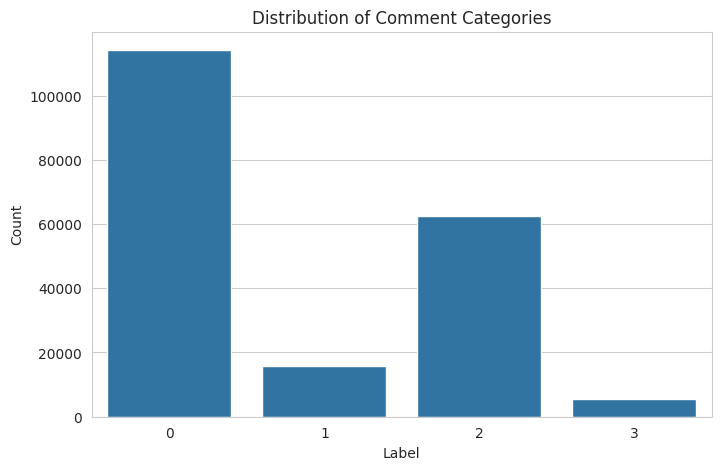

Label value counts:
 label
0    114173
2     62440
1     15918
3      5469
Name: count, dtype: int64


In [5]:
# ------------------------------
# 4. Exploratory Data Analysis (EDA)
# ------------------------------
# Set style
sns.set_style('whitegrid')

# 4.1 Distribution of target variable (label)
plt.figure(figsize=(8,5))
sns.countplot(data=train, x='label')
plt.title('Distribution of Comment Categories')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()
# Insight: The classes might be balanced? We'll check the counts.
print("Label value counts:\n", train['label'].value_counts())

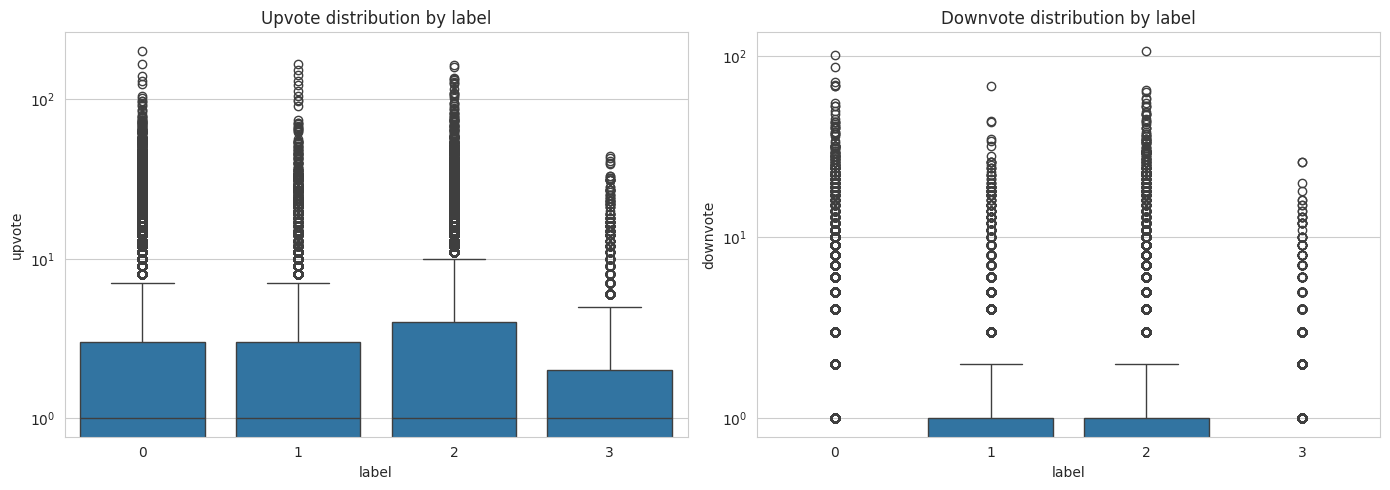

In [6]:
# 4.2 Relationship between upvotes/downvotes and label
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.boxplot(data=train, x='label', y='upvote', ax=axes[0])
axes[0].set_title('Upvote distribution by label')
axes[0].set_yscale('log')  # because upvotes might be skewed

sns.boxplot(data=train, x='label', y='downvote', ax=axes[1])
axes[1].set_title('Downvote distribution by label')
axes[1].set_yscale('log')
plt.tight_layout()
plt.show()
# Insight: Certain categories may receive more upvotes/downvotes.

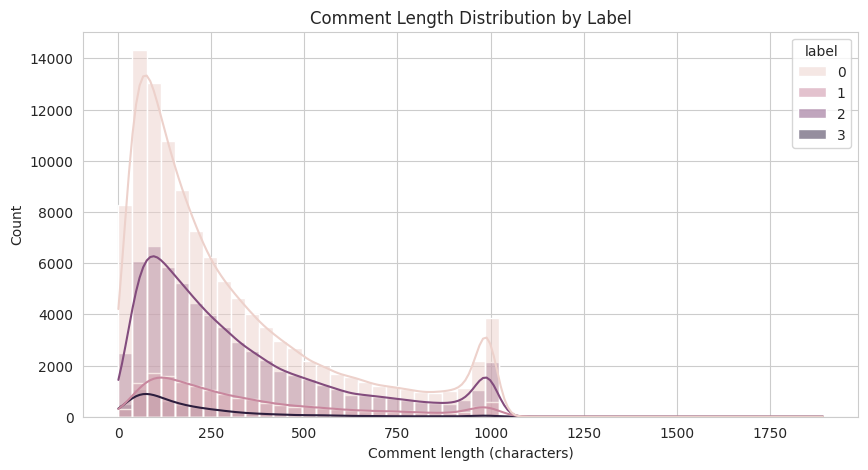

In [7]:
# 4.3 Comment length analysis
train['comment_len'] = train['comment'].astype(str).apply(len)
plt.figure(figsize=(10,5))
sns.histplot(data=train, x='comment_len', hue='label', bins=50, kde=True)
plt.title('Comment Length Distribution by Label')
plt.xlabel('Comment length (characters)')
plt.show()
# Insight: Different categories might have different comment lengths.

# Remove temporary column (will be handled in feature engineering)
train.drop('comment_len', axis=1, inplace=True)

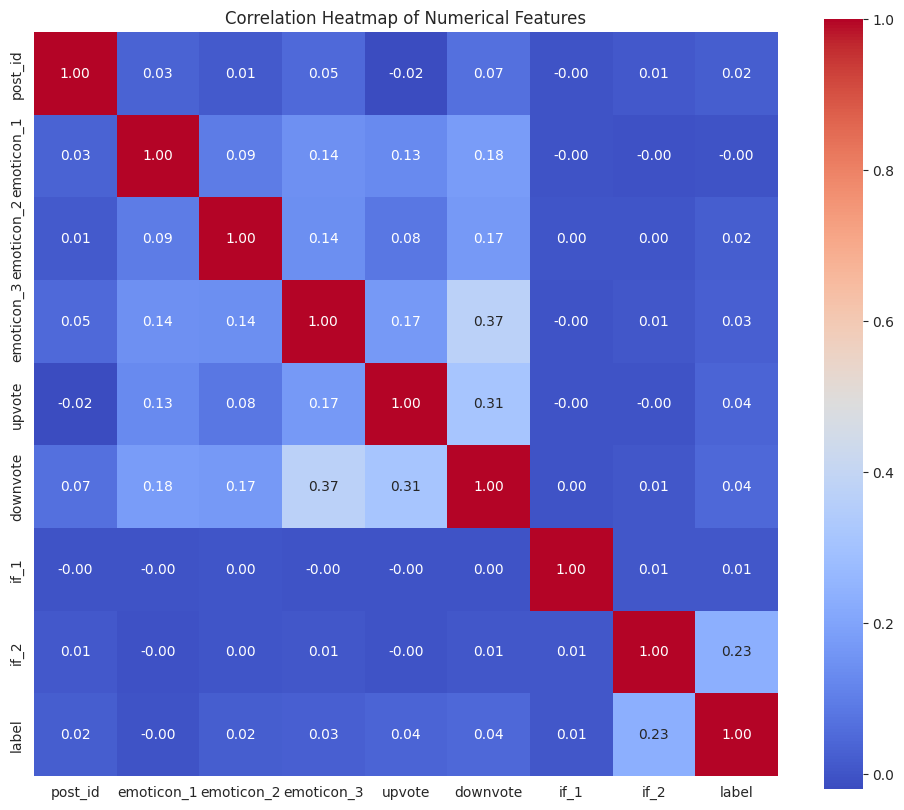

In [8]:
# 4.4 Correlation heatmap of numerical features
numerical_df = train.select_dtypes(include=[np.number])
plt.figure(figsize=(12, 10))
sns.heatmap(numerical_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

## 4. Feature engineering

- Categorical topic indicators (race, religion, gender): missing values mapped to a `missing` category
- Emoticon, vote and internal-signal columns converted to numeric
- Timestamp split into year, month, day, hour and day of week
- Text statistics: character length, word count, exclamation and question-mark counts
- Upvote and downvote outliers capped at the 99th percentile learned from the training data only

In [28]:
# ----------------------------------------------------------
# Feature Engineering Function (UPDATED)
# ----------------------------------------------------------
def engineer_features(df, is_train=True, caps_dict=None):
    """Apply feature engineering to a dataframe safely."""
    df = df.copy()
    if caps_dict is None:
        caps_dict = {}
    
    # --- 1. Handle Categorical Columns ---
    cat_cols = ['race', 'religion', 'gender']
    for col in cat_cols:
        if col in df.columns:
            # Replace literal string 'none' and actual NaNs with 'missing'
            df[col] = df[col].replace('none', np.nan).fillna('missing').astype(str)
            
    # Disability is actually boolean, so we can convert it to 0/1 safely
    if 'disability' in df.columns:
        df['disability'] = df['disability'].fillna(False).astype(int)
    
    # --- 2. Emoticon columns (counts) ---
    emoticon_cols = ['emoticon_1', 'emoticon_2', 'emoticon_3']
    for col in emoticon_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
    
    # --- 3. Comment text ---
    if 'comment' in df.columns:
        df['comment'] = df['comment'].fillna('')
    
    # --- 4. Other numeric columns ---
    other_num = ['upvote', 'downvote', 'if_1', 'if_2']
    for col in other_num:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    
    # --- 5. Drop post_id ---
    if 'post_id' in df.columns:
        df.drop('post_id', axis=1, inplace=True)
    
    # --- 6. Process created_date ---
    if 'created_date' in df.columns:
        df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
        df['created_year'] = df['created_date'].dt.year
        df['created_month'] = df['created_date'].dt.month
        df['created_day'] = df['created_date'].dt.day
        df['created_hour'] = df['created_date'].dt.hour
        df['created_dayofweek'] = df['created_date'].dt.dayofweek
        df.drop('created_date', axis=1, inplace=True)
        # Fill any missing datetime components with 0
        for col in ['created_year', 'created_month', 'created_day', 'created_hour', 'created_dayofweek']:
            df[col] = df[col].fillna(0).astype(int)
    
    # --- 7. Basic text features ---
    if 'comment' in df.columns:
        df['comment_char_len'] = df['comment'].apply(len)
        df['comment_word_len'] = df['comment'].apply(lambda x: len(x.split()))
        df['num_exclamation'] = df['comment'].apply(lambda x: x.count('!'))
        df['num_question'] = df['comment'].apply(lambda x: x.count('?'))
    
    # --- 8. Outlier  ---
    if is_train:
        upvote_99 = df['upvote'].quantile(0.99)
        downvote_99 = df['downvote'].quantile(0.99)
        caps_dict['upvote_cap'] = upvote_99
        caps_dict['downvote_cap'] = downvote_99
    
    if 'upvote' in df.columns and 'upvote_cap' in caps_dict:
        df['upvote'] = np.where(df['upvote'] > caps_dict['upvote_cap'], caps_dict['upvote_cap'], df['upvote'])
    if 'downvote' in df.columns and 'downvote_cap' in caps_dict:
        df['downvote'] = np.where(df['downvote'] > caps_dict['downvote_cap'], caps_dict['downvote_cap'], df['downvote'])
    
    return df, caps_dict 

In [29]:
# ----------------------------------------------------------
# Apply Feature Engineering and Split X/y (UPDATED)
# ----------------------------------------------------------
# Apply to train and extract the calculated outlier limits
train_eng, limits_dict = engineer_features(train, is_train=True)

# Apply to test using the limits learned STRICTLY from the training data
test_eng, _ = engineer_features(test, is_train=False, caps_dict=limits_dict)

# Now separate features and target for training
X = train_eng.drop('label', axis=1)
y = train_eng['label'] 

## 5. Train / validation split

Stratified 80/20 split to keep the class balance the same in both sets.

In [30]:
# ------------------------------
# Train-Validation Split
# ------------------------------
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train size: {X_train.shape}, Validation size: {X_val.shape}") 

Train size: (158400, 21), Validation size: (39600, 21)


In [31]:
print("Columns in X:", X.columns.tolist()) 

Columns in X: ['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender', 'disability', 'comment', 'created_year', 'created_month', 'created_day', 'created_hour', 'created_dayofweek', 'comment_char_len', 'comment_word_len', 'num_exclamation', 'num_question']


## 6. Baseline preprocessing pipeline

Median imputation and scaling for numeric columns, one-hot encoding for categorical columns, and a 5,000-feature TF-IDF on the comment text.

In [32]:
# ------------------------------
# Preprocessing Pipelines (UPDATED)
# ------------------------------
# 1. Define feature groups explicitly
categorical_cols = ['race', 'religion', 'gender']
text_col = 'comment'

# All other columns are numerical
num_cols = [
    'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2',
    'disability', 'created_year', 'created_month', 'created_day', 'created_hour', 
    'created_dayofweek', 'comment_char_len', 'comment_word_len', 
    'num_exclamation', 'num_question'
]

# 2. Define numeric transformer: impute + scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 3. Define categorical transformer: encode!
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')), # safety net
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 4. Define text transformer: TF-IDF with max 5000 features
text_transformer = Pipeline(steps=[
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', lowercase=True))
])

# 5. Combine using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, categorical_cols),
        ('text', text_transformer, text_col)
    ],
    remainder='drop'
)

sample_preprocessed = preprocessor.fit_transform(X_train.head(100))
print(f"Preprocessed feature matrix shape: {sample_preprocessed.shape}") 

Preprocessed feature matrix shape: (100, 1679)


In [33]:
# ----------------------------------------------------------
# Apply Preprocessor to Full Datasets
# ----------------------------------------------------------
print("Transforming the full training data...")
# fit_transform on training data
X_train_processed = preprocessor.fit_transform(X_train)

print("Transforming the validation data...")

X_val_processed = preprocessor.transform(X_val)

print(f"Full Processed X_train shape: {X_train_processed.shape}")
print(f"Full Processed X_val shape: {X_val_processed.shape}") 

Transforming the full training data...
Transforming the validation data...
Full Processed X_train shape: (158400, 5036)
Full Processed X_val shape: (39600, 5036)


## 7. Final model: dual TF-IDF + class-weighted LightGBM

- **Word TF-IDF:** unigrams and bigrams, 15,000 features
- **Character TF-IDF:** 3- to 5-character n-grams, 10,000 features
- **LightGBM** with `num_leaves=63` and custom class weights to give the two minority classes more weight

This is the model behind the submitted result (private leaderboard 0.81644).

Setting up Dual TF-IDF Preprocessor...
Transforming all data (Extracting 25,000 text features)...
Training High-Capacity LightGBM...

Evaluating on Validation Set...

--- Dual TF-IDF Validation Accuracy: 0.9158 ---

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.95      0.96     22835
           1       0.75      0.82      0.79      3183
           2       0.87      0.90      0.89     12488
           3       0.65      0.69      0.67      1094

    accuracy                           0.92     39600
   macro avg       0.81      0.84      0.83     39600
weighted avg       0.92      0.92      0.92     39600



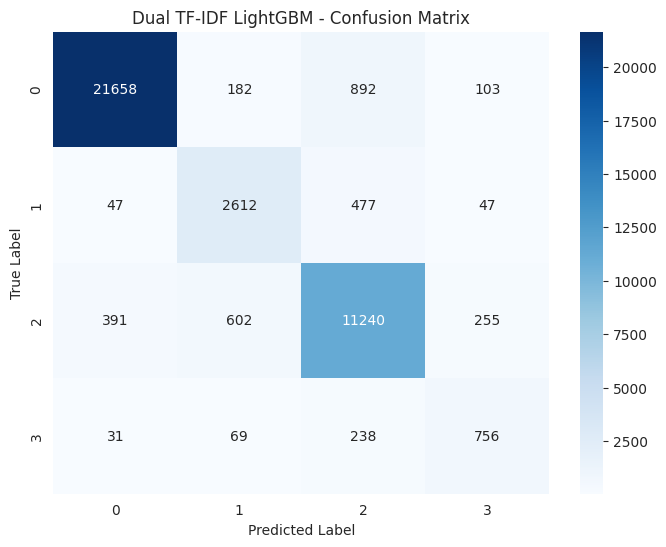


Predicting on Kaggle Test Set...
Successfully saved to submission.csv


In [50]:
# ----------------------------------------------------------
# Dual TF-IDF Pipeline (Word + Character)
# ----------------------------------------------------------
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import lightgbm as lgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Setting up Dual TF-IDF Preprocessor...")

# 1. Feature Groupings
cat_cols = ['race', 'religion', 'gender']
num_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 
            'num_exclamation', 'num_question', 'disability', 'created_year', 'created_month', 
            'created_day', 'comment_char_len', 'comment_word_len', 'created_hour', 'created_dayofweek']

# 2. Dual TF-IDF Vectorizers for comprehensive text capture
word_tfidf = TfidfVectorizer(analyzer='word', max_features=15000, ngram_range=(1,2), stop_words='english', lowercase=True)
char_tfidf = TfidfVectorizer(analyzer='char', max_features=10000, ngram_range=(3,5), lowercase=True)

# 3. Basic Pipelines (Scaling intentionally omitted for Tree-based models)
cat_trans = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')), 
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
num_trans = SimpleImputer(strategy='median') 

# 4. Master Preprocessor
preprocessor_dual = ColumnTransformer([
    ('cat', cat_trans, cat_cols), 
    ('num', num_trans, num_cols),
    ('word_features', word_tfidf, 'comment'), 
    ('char_features', char_tfidf, 'comment')             
])

# 5. Transform Data
print("Transforming all data (Extracting 25,000 text features)...")
X_train_dual = preprocessor_dual.fit_transform(X_train)
X_val_dual = preprocessor_dual.transform(X_val)
X_test_dual = preprocessor_dual.transform(test_eng)

# 6. Train High-Capacity LightGBM
print("Training High-Capacity LightGBM...")
custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}

lgb_dual_model = lgb.LGBMClassifier(
    num_leaves=63,             # Increased capacity to handle 25k features
    class_weight=custom_weights_dict, 
    random_state=42, 
    verbose=-1
)
lgb_dual_model.fit(X_train_dual, y_train)

# 7. Evaluate on Validation Set
print("\nEvaluating on Validation Set...")
val_preds_dual = lgb_dual_model.predict(X_val_dual)

print(f"\n--- Dual TF-IDF Validation Accuracy: {accuracy_score(y_val, val_preds_dual):.4f} ---")
print("\nClassification Report:")
print(classification_report(y_val, val_preds_dual))

# Confusion Matrix
plt.figure(figsize=(8, 6))
cm_dual = confusion_matrix(y_val, val_preds_dual)
sns.heatmap(cm_dual, annot=True, fmt='d', cmap='Blues',
            xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
plt.title("Dual TF-IDF LightGBM - Confusion Matrix")
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# 8. Generate Kaggle Submission
print("\nPredicting on Kaggle Test Set...")
test_preds_dual = lgb_dual_model.predict(X_test_dual)

submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_dual})
submission_df.to_csv('submission.csv', index=False)
print("Successfully saved to submission.csv") 

## Appendix: earlier experiments

Models tried during development, kept for reference. These cells are commented out because they were not part of the final run (several take a long time to train).

They include Dummy, Logistic Regression, SGD, Complement Naive Bayes, KNN, SVM, Decision Tree, Random Forest, MLP, XGBoost, LightGBM, CatBoost, PCA/SVD + Logistic Regression, averaging and stacking ensembles, and VADER sentiment features.

In [9]:
# # ----------------------------------------------------------
# # Feature Engineering Function
# # ----------------------------------------------------------
# def engineer_features(df, is_train=True):
#     """Apply feature engineering to a dataframe."""
#     df = df.copy()
    
#     # --- Handle missing values in a column-specific way ---
#     # 1. Indicator columns (race, religion, gender, disability): convert to 0/1, fill missing with 0
#     indicator_cols = ['race', 'religion', 'gender', 'disability']
#     for col in indicator_cols:
#         if col in df.columns:
#             # Convert to numeric (coerce errors to NaN), then fill NaN with 0, then int
#             df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
    
#     # 2. Emoticon columns (counts) – ensure they are numeric, fill missing with 0
#     emoticon_cols = ['emoticon_1', 'emoticon_2', 'emoticon_3']
#     for col in emoticon_cols:
#         if col in df.columns:
#             df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
    
#     # 3. Comment text – fill missing with empty string
#     if 'comment' in df.columns:
#         df['comment'] = df['comment'].fillna('')
    
#     # 4. Other numeric columns (upvote, downvote, if_1, if_2) – fill missing with 0 (just in case)
#     other_num = ['upvote', 'downvote', 'if_1', 'if_2']
#     for col in other_num:
#         if col in df.columns:
#             df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    
#     # --- Drop post_id ---
#     if 'post_id' in df.columns:
#         df.drop('post_id', axis=1, inplace=True)
    
#     # --- Process created_date ---
#     if 'created_date' in df.columns:
#         df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
#         df['created_year'] = df['created_date'].dt.year
#         df['created_month'] = df['created_date'].dt.month
#         df['created_day'] = df['created_date'].dt.day
#         df['created_hour'] = df['created_date'].dt.hour
#         df['created_dayofweek'] = df['created_date'].dt.dayofweek
#         df.drop('created_date', axis=1, inplace=True)
#         # Fill any missing datetime components with 0
#         for col in ['created_year', 'created_month', 'created_day', 'created_hour', 'created_dayofweek']:
#             df[col] = df[col].fillna(0).astype(int)
    
#     # --- Basic text features from 'comment' ---
#     if 'comment' in df.columns:
#         df['comment_char_len'] = df['comment'].apply(len)
#         df['comment_word_len'] = df['comment'].apply(lambda x: len(x.split()))
    
#     # --- Outlier capping for upvote/downvote (only on training data) ---
#     if is_train:
#         upvote_99 = df['upvote'].quantile(0.99)
#         downvote_99 = df['downvote'].quantile(0.99)
#         # Store thresholds for test
#         global upvote_cap, downvote_cap
#         upvote_cap = upvote_99
#         downvote_cap = downvote_99
#         df['upvote'] = np.where(df['upvote'] > upvote_99, upvote_99, df['upvote'])
#         df['downvote'] = np.where(df['downvote'] > downvote_99, downvote_99, df['downvote'])
#     else:
#         if 'upvote' in df.columns:
#             df['upvote'] = np.where(df['upvote'] > upvote_cap, upvote_cap, df['upvote'])
#             df['downvote'] = np.where(df['downvote'] > downvote_cap, downvote_cap, df['downvote'])
    
#     return df 

In [10]:
# # Apply to train and test
# train_eng = engineer_features(train, is_train=True)
# test_eng = engineer_features(test, is_train=False)

# # Now separate features and target
# X = train_eng.drop('label', axis=1)
# y = train_eng['label']

In [11]:
# # ------------------------------
# # 6. Train-Validation Split
# # ------------------------------
# X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# print(f"Train size: {X_train.shape}, Validation size: {X_val.shape}") 

In [12]:
# print("Columns in X:", X.columns.tolist())

In [13]:
# # ------------------------------
# # 7. Preprocessing Pipelines
# # ------------------------------
# # Identify numeric columns (all except 'comment')
# num_cols = ['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2',
#             'race', 'religion', 'gender', 'disability',
#             'created_year', 'created_month', 'created_day', 'created_hour', 'created_dayofweek',
#             'comment_char_len', 'comment_word_len']
# # (We can also generate dynamically: num_cols = [col for col in X.columns if col != 'comment'])

# # Define numeric transformer: impute (just in case) + scale
# numeric_transformer = Pipeline(steps=[
#     ('imputer', SimpleImputer(strategy='median')),  # safety net
#     ('scaler', StandardScaler())
# ])

# # Define text transformer: TF-IDF with max 5000 features
# text_transformer = Pipeline(steps=[
#     ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', lowercase=True))
# ])

# # Combine using ColumnTransformer
# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', numeric_transformer, num_cols),
#         ('text', text_transformer, 'comment')
#     ])

# # Verify the preprocessor creates the expected number of features
# # (Optional) Fit on a small sample to check
# sample_preprocessed = preprocessor.fit_transform(X_train.head(100))
# print(f"Preprocessed feature matrix shape: {sample_preprocessed.shape}") 

In [14]:
# ==============================================
# Model 1: DummyClassifier
# ==============================================

# Build pipeline
#dummy_pipe = Pipeline(steps=[
#    ('preprocessor', preprocessor),
#    ('classifier', DummyClassifier(strategy='most_frequent'))
#])

# Train on full training data
#dummy_pipe.fit(X, y)

# Predict on test set
#test_preds = dummy_pipe.predict(test_eng)

# Prepare submission (using sample_submission format)
#submission = sample_sub.copy()
#submission['label'] = test_preds

# Save as submission.csv (required name for Kaggle)
#submission.to_csv('submission.csv', index=False)
#print("submission.csv created successfully.")
#print("First 5 rows:")
#print(submission.head()) 

In [15]:
# ==============================================
# Model 2: Logistic Regression (Tuned)
# ==============================================
#from sklearn.linear_model import LogisticRegression
#from sklearn.model_selection import GridSearchCV
#import os

# Define pipeline (preprocessor + logistic regression)
#lr_pipe = Pipeline(steps=[
#    ('preprocessor', preprocessor),
#    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
#])

# Hyperparameter grid
#param_grid_lr = {
#    'classifier__C': [0.01, 0.1, 1, 10],
#    'classifier__penalty': ['l2'],          # l2 is default and works with lbfgs/saga
#    'classifier__solver': ['lbfgs', 'saga'] # saga supports l2 and elasticnet, but we stick to l2
#}

# Perform grid search with 3-fold CV 
#grid_search = GridSearchCV(lr_pipe, param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
#grid_search.fit(X, y)   # Train on full training data

#print("Best parameters:", grid_search.best_params_)
#print("Best cross-validation accuracy: {:.4f}".format(grid_search.best_score_))

# Predict on test set using the best estimator
#test_preds = grid_search.predict(test_eng)

# Prepare submission
#submission = sample_sub.copy()
#submission['label'] = test_preds
#submission.to_csv('submission.csv', index=False)

#print("submission.csv created for Logistic Regression.")
#print("First 5 rows:")
#print(submission.head())

In [16]:
# ==============================================
# Model 3: SGDClassifier (Tuned)
# ==============================================
#from sklearn.linear_model import SGDClassifier
#from sklearn.model_selection import GridSearchCV

# Define pipeline with SGDClassifier
#sgd_pipe = Pipeline(steps=[
#    ('preprocessor', preprocessor),
#    ('classifier', SGDClassifier(random_state=42, max_iter=1000, tol=1e-3))
#])

# Hyperparameter grid for SGD
#param_grid_sgd = {
#    'classifier__loss': ['log_loss', 'modified_huber'],  # 'log_loss' gives probabilistic output
#    'classifier__penalty': ['l2', 'elasticnet'],
#    'classifier__alpha': [0.0001, 0.001, 0.01],
#    'classifier__l1_ratio': [0.15, 0.5]  # only used if penalty='elasticnet'
#}

# Perform grid search with 3-fold CV
#grid_search_sgd = GridSearchCV(sgd_pipe, param_grid_sgd, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
#grid_search_sgd.fit(X, y)

#print("Best SGD parameters:", grid_search_sgd.best_params_)
#print("Best SGD CV accuracy: {:.4f}".format(grid_search_sgd.best_score_))

# Predict on test set
#test_preds_sgd = grid_search_sgd.predict(test_eng)

# Prepare submission
#submission = sample_sub.copy()
#submission['label'] = test_preds_sgd
#submission.to_csv('submission.csv', index=False)

#print("submission.csv created for SGDClassifier.")
#print("First 5 rows:")
#print(submission.head()) 

In [17]:
# ==============================================
# Model 1: Complement Naive Bayes
# (non‑negative preprocessing)
# ==============================================

#import warnings
#warnings.filterwarnings("ignore")

#from sklearn.naive_bayes import ComplementNB
#from sklearn.feature_selection import SelectKBest, mutual_info_classif
#from sklearn.pipeline import Pipeline
#from sklearn.model_selection import GridSearchCV
#from sklearn.preprocessing import MaxAbsScaler
#from sklearn.impute import SimpleImputer 
#from sklearn.compose import ColumnTransformer
#from sklearn.feature_extraction.text import TfidfVectorizer

# Dynamically get numeric columns (all columns except 'comment')
#num_cols = [col for col in X.columns if col != 'comment']

# Numeric transformer with MaxAbsScaler (keeps non‑negative)
#numeric_transformer_nb = Pipeline(steps=[
#    ('imputer', SimpleImputer(strategy='median')),   # safety net
#    ('scaler', MaxAbsScaler())                       # scales to [0,1] (if input non‑negative)
#])

# Text transformer (TF‑IDF outputs non‑negative values)
#text_transformer_nb = Pipeline(steps=[
#    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', lowercase=True))
#])

# Combined preprocessor for NB
#preprocessor_nb = ColumnTransformer(
#    transformers=[
#        ('num', numeric_transformer_nb, num_cols),
#        ('text', text_transformer_nb, 'comment')
#    ])

# Full pipeline with feature selection and ComplementNB
#nb_pipe = Pipeline(steps=[
#    ('preprocessor', preprocessor_nb),
#    ('select', SelectKBest(score_func=mutual_info_classif)),
#    ('classifier', ComplementNB())
#])

# Hyperparameter grid
#param_grid_nb = {
#    'select__k': [1000, 2000, 5000],
#    'classifier__alpha': [0.1, 0.5, 1.0]          # smoothing parameter
#}

# Grid search with 3‑fold CV
#grid_nb = GridSearchCV(nb_pipe, param_grid_nb, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
#grid_nb.fit(X, y)   # X and y are your full training data (from earlier steps)

#print("Best ComplementNB parameters:", grid_nb.best_params_)
#print("Best CV accuracy: {:.4f}".format(grid_nb.best_score_))

# Predict on test set and create submission.csv
#test_preds_nb = grid_nb.predict(test_eng)          # test_eng is your engineered test data
#submission = sample_sub.copy()
#submission['label'] = test_preds_nb
#submission.to_csv('submission.csv', index=False)

#print("submission.csv created for ComplementNB.")
#print("First 5 rows:")
#print(submission.head()) 

In [18]:
# ==============================================
# Model 2: KNN with reduced features & minimal grid
# ==============================================

#import warnings
#warnings.filterwarnings("ignore")

#import numpy as np
#from sklearn.neighbors import KNeighborsClassifier
#from sklearn.feature_selection import SelectKBest, mutual_info_classif
#from sklearn.pipeline import Pipeline
#from sklearn.model_selection import GridSearchCV
#from sklearn.feature_extraction.text import TfidfVectorizer
#from sklearn.preprocessing import StandardScaler
#from sklearn.impute import SimpleImputer
#from sklearn.compose import ColumnTransformer

# ------------------------------------------------------------
# 1. Build preprocessor for KNN (using 2000 TF-IDF features for speed)
# ------------------------------------------------------------
# get numeric columns (all except 'comment')
#num_cols = [col for col in X.columns if col != 'comment']

#numeric_transformer = Pipeline(steps=[
#    ('imputer', SimpleImputer(strategy='median')),
#    ('scaler', StandardScaler())
#])

#text_transformer = Pipeline(steps=[
#    ('tfidf', TfidfVectorizer(max_features=2000, stop_words='english', lowercase=True))
#])

#preprocessor_knn = ColumnTransformer(
#    transformers=[
#        ('num', numeric_transformer, num_cols),
#        ('text', text_transformer, 'comment')
#    ])

# ------------------------------------------------------------
# 2. Pipeline with fixed feature selection (k=2000)
# ------------------------------------------------------------
#knn_pipe = Pipeline(steps=[
#    ('preprocessor', preprocessor_knn),
#    ('select', SelectKBest(score_func=mutual_info_classif, k=2000)),
#    ('classifier', KNeighborsClassifier(n_jobs=-1))
#])

# ------------------------------------------------------------
# 3. Minimal hyperparameter grid
# ------------------------------------------------------------
#param_grid_knn = {
#    'classifier__n_neighbors': [5, 11],
#    'classifier__weights': ['distance']          # better than uniform
#}

# ------------------------------------------------------------
# 4. Grid search with full training data (3 folds)
# ------------------------------------------------------------
#grid_knn = GridSearchCV(knn_pipe, param_grid_knn, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
#grid_knn.fit(X, y)

#print("Best KNN parameters:", grid_knn.best_params_)
#print("Best CV accuracy: {:.4f}".format(grid_knn.best_score_))

# ------------------------------------------------------------
# 5. Predict and create submission.csv
# ------------------------------------------------------------
#test_preds_knn = grid_knn.predict(test_eng)
#submission = sample_sub.copy()
#submission['label'] = test_preds_knn
#submission.to_csv('submission.csv', index=False)

#print("submission.csv created for KNN.")
#print("First 5 rows:")
#print(submission.head()) 

In [19]:
# ==============================================
# Model 3: Support Vector Machine
# ==============================================

#import warnings
#warnings.filterwarnings("ignore")

#from sklearn.svm import LinearSVC
#from sklearn.pipeline import Pipeline
#from sklearn.model_selection import GridSearchCV
#from sklearn.preprocessing import StandardScaler
#from sklearn.impute import SimpleImputer
#from sklearn.compose import ColumnTransformer
#from sklearn.feature_extraction.text import TfidfVectorizer

# ------------------------------------------------------------
# 1. preprocessor (same as original: StandardScaler + TF‑IDF with 5000 features)
# ------------------------------------------------------------
#num_cols = [col for col in X.columns if col != 'comment']

#numeric_transformer = Pipeline(steps=[
#    ('imputer', SimpleImputer(strategy='median')),
#    ('scaler', StandardScaler())
#])

#text_transformer = Pipeline(steps=[
#    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', lowercase=True))
#])

#preprocessor_svm = ColumnTransformer(
#    transformers=[
#        ('num', numeric_transformer, num_cols),
#        ('text', text_transformer, 'comment')
#    ])

# ------------------------------------------------------------
# 2. Pipeline with LinearSVC
# ------------------------------------------------------------
#svm_pipe = Pipeline(steps=[
#    ('preprocessor', preprocessor_svm),
#    ('classifier', LinearSVC(random_state=42, max_iter=2000, dual=False))   # dual=False for n_samples > n_features
#])

# ------------------------------------------------------------
# 3. Hyperparameter grid
# ------------------------------------------------------------
#param_grid_svm = {
#    'classifier__C': [0.1, 1, 10],                   # regularization strength
#    'classifier__class_weight': [None, 'balanced']   # handle potential class imbalance
#}

# ------------------------------------------------------------
# 4. Grid search with 3‑fold CV (6 fits total)
# ------------------------------------------------------------
#grid_svm = GridSearchCV(svm_pipe, param_grid_svm, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
#grid_svm.fit(X, y)   # full training data

#print("Best LinearSVC parameters:", grid_svm.best_params_)
#print("Best CV accuracy: {:.4f}".format(grid_svm.best_score_))

# ------------------------------------------------------------
# 5. Predict on test set and create submission.csv
# ------------------------------------------------------------
#test_preds_svm = grid_svm.predict(test_eng)
#submission = sample_sub.copy()
#submission['label'] = test_preds_svm
#submission.to_csv('submission.csv', index=False)

#print("submission.csv created for LinearSVC.")
#print("First 5 rows:")
#print(submission.head()) 

In [20]:
# ==============================================
# Model 1: XGBoost (Boosting)
# with hyperparameter tuning
# ==============================================

#import warnings
#warnings.filterwarnings("ignore")

#from xgboost import XGBClassifier
#from sklearn.pipeline import Pipeline
#from sklearn.model_selection import GridSearchCV
#from sklearn.preprocessing import StandardScaler
#from sklearn.impute import SimpleImputer
#from sklearn.compose import ColumnTransformer
#from sklearn.feature_extraction.text import TfidfVectorizer

# ------------------------------------------------------------
# 1. Build preprocessor (original: StandardScaler + TF‑IDF with 5000 features)
# ------------------------------------------------------------
#num_cols = [col for col in X.columns if col != 'comment']

#numeric_transformer = Pipeline(steps=[
#    ('imputer', SimpleImputer(strategy='median')),
#    ('scaler', StandardScaler())
#])

#text_transformer = Pipeline(steps=[
#    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', lowercase=True))
#])

#preprocessor_xgb = ColumnTransformer(
#    transformers=[
#        ('num', numeric_transformer, num_cols),
#        ('text', text_transformer, 'comment')
#    ])

# ------------------------------------------------------------
# 2. Pipeline with XGBClassifier
# ------------------------------------------------------------
#xgb_pipe = Pipeline(steps=[
#    ('preprocessor', preprocessor_xgb),
#    ('classifier', XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss'))
#])

# ------------------------------------------------------------
# 3. Hyperparameter grid
# ------------------------------------------------------------
#param_grid_xgb = {
#    'classifier__learning_rate': [0.1, 0.3],
#    'classifier__max_depth': [3, 6],
#    'classifier__n_estimators': [100, 200]
#}

# ------------------------------------------------------------
# 4. Grid search with 3‑fold CV
# ------------------------------------------------------------
#grid_xgb = GridSearchCV(xgb_pipe, param_grid_xgb, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
#grid_xgb.fit(X, y)

#print("Best XGBoost parameters:", grid_xgb.best_params_)
#print("Best CV accuracy: {:.4f}".format(grid_xgb.best_score_))

# ------------------------------------------------------------
# 5. Predict and create submission.csv
# ------------------------------------------------------------
#test_preds_xgb = grid_xgb.predict(test_eng)
#submission = sample_sub.copy()
#submission['label'] = test_preds_xgb
#submission.to_csv('submission.csv', index=False)

#print("submission.csv created for XGBoost.")
#print("First 5 rows:")
#print(submission.head()) 

In [21]:
# ==============================================
# Model 2: LightGBM (Boosting)
# with hyperparameter tuning
# ==============================================

#import warnings
#warnings.filterwarnings("ignore")

#import lightgbm as lgb
#from sklearn.pipeline import Pipeline
#from sklearn.model_selection import GridSearchCV
#from sklearn.preprocessing import StandardScaler
#from sklearn.impute import SimpleImputer
#from sklearn.compose import ColumnTransformer
#from sklearn.feature_extraction.text import TfidfVectorizer

# ------------------------------------------------------------
# 1. Build preprocessor (StandardScaler + TF‑IDF with 5000 features)
# ------------------------------------------------------------
#num_cols = [col for col in X.columns if col != 'comment']

#numeric_transformer = Pipeline(steps=[
#    ('imputer', SimpleImputer(strategy='median')),
#    ('scaler', StandardScaler())
#])

#text_transformer = Pipeline(steps=[
#    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', lowercase=True))
#])

#preprocessor_lgb = ColumnTransformer(
#    transformers=[
#        ('num', numeric_transformer, num_cols),
#        ('text', text_transformer, 'comment')
#    ])

# ------------------------------------------------------------
# 2. Pipeline with LightGBM
# ------------------------------------------------------------
#lgb_pipe = Pipeline(steps=[
#    ('preprocessor', preprocessor_lgb),
#    ('classifier', lgb.LGBMClassifier(random_state=42, verbose=-1))
#])

# ------------------------------------------------------------
# 3. Hyperparameter grid
# ------------------------------------------------------------
#param_grid_lgb = {
#    'classifier__learning_rate': [0.1, 0.3],
#    'classifier__max_depth': [3, 6],
#    'classifier__n_estimators': [100, 200],
#    'classifier__num_leaves': [31, 63]
#}

# ------------------------------------------------------------
# 4. Grid search with 3‑fold CV
# ------------------------------------------------------------
#grid_lgb = GridSearchCV(lgb_pipe, param_grid_lgb, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
#grid_lgb.fit(X, y)

#print("Best LightGBM parameters:", grid_lgb.best_params_)
#print("Best CV accuracy: {:.4f}".format(grid_lgb.best_score_))

# ------------------------------------------------------------
# 5. Predict and create submission.csv
# ------------------------------------------------------------
#test_preds_lgb = grid_lgb.predict(test_eng)
#submission = sample_sub.copy()
#submission['label'] = test_preds_lgb
#submission.to_csv('submission.csv', index=False)

#print("submission.csv created for LightGBM.")
#print("First 5 rows:")
#print(submission.head()) 

In [22]:
# ==============================================
# Optimized LightGBM
# ==============================================

#import warnings
#arnings.filterwarnings("ignore")

#import numpy as np
#import pandas as pd
#from sklearn.model_selection import GridSearchCV
#from sklearn.pipeline import Pipeline
#from sklearn.compose import ColumnTransformer
#from sklearn.impute import SimpleImputer
#from sklearn.feature_extraction.text import TfidfVectorizer
#from sklearn.preprocessing import FunctionTransformer, StandardScaler
#import lightgbm as lgb

# ------------------------------------------------------------
# 1. Define custom transformers for log transform and cyclic encoding
# ------------------------------------------------------------
#def log_transform(X):
#    return np.log1p(X)   # log1p = log(1+x) safe for zeros

#log_transformer = FunctionTransformer(log_transform, validate=False)

#def cyclic_encoding(X, period):
    # X is 1D array, returns two columns: sin(2π*x/period), cos(...)
#    sin = np.sin(2 * np.pi * X / period)
#    cos = np.cos(2 * np.pi * X / period)
#    return np.column_stack([sin, cos])

# We'll apply cyclic encoding manually in the pipeline using FunctionTransformer
# For hour: period=24, for dayofweek: period=7
# ------------------------------------------------------------

# ------------------------------------------------------------
# 2. Build preprocessor without scaling
# ------------------------------------------------------------
# Numeric columns that we will log-transform
#log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 
#            'emoticon_1', 'emoticon_2', 'emoticon_3']

# Other numeric columns that remain as is (binary indicators, lengths, etc.)
#other_num_cols = ['race', 'religion', 'gender', 'disability',
#                  'created_year', 'created_month', 'created_day',
#                  'comment_char_len', 'comment_word_len']

# Columns that need cyclic encoding: 'created_hour', 'created_dayofweek'
# We'll handle them separately: apply cyclic encoding, then they become two columns each.

# ------------------------------------------------------------
# We'll use ColumnTransformer with three branches:
# - Log-transformed columns (log1p)
# - Other numeric columns (no transformation, just impute)
# - Cyclic encoded columns (hour and dayofweek)
# - Text (TF-IDF)
# ------------------------------------------------------------

# Branch 1: Log-transform
#log_trans = Pipeline([
#    ('imputer', SimpleImputer(strategy='median')),
#    ('log', log_transformer)
#])

# Branch 2: Other numeric (just impute, no scale)
#other_num_trans = Pipeline([
#    ('imputer', SimpleImputer(strategy='median'))
#])

# Branch 3: Cyclic encoding for hour and dayofweek
#def cyclic_hour(X):
    # X is a column (1D) for hour
#    sin = np.sin(2 * np.pi * X / 24)
#    cos = np.cos(2 * np.pi * X / 24)
#    return np.column_stack([sin, cos])

#def cyclic_dow(X):
#    sin = np.sin(2 * np.pi * X / 7)
#    cos = np.cos(2 * np.pi * X / 7)
#    return np.column_stack([sin, cos])

#hour_trans = Pipeline([
#    ('imputer', SimpleImputer(strategy='median')),
#    ('cyclic', FunctionTransformer(cyclic_hour, validate=False))
#])
#dow_trans = Pipeline([
#    ('imputer', SimpleImputer(strategy='median')),
#    ('cyclic', FunctionTransformer(cyclic_dow, validate=False))
#])

# Branch 4: Text
#text_trans = TfidfVectorizer(max_features=8000, stop_words='english', 
#                             lowercase=True, ngram_range=(1,2))

# Combine all
#preprocessor_lgb_opt = ColumnTransformer(
#    transformers=[
#        ('log', log_trans, log_cols),
#        ('other', other_num_trans, other_num_cols),
#        ('hour_cyclic', hour_trans, ['created_hour']),
#        ('dow_cyclic', dow_trans, ['created_dayofweek']),
#        ('text', text_trans, 'comment')
#    ])

# ------------------------------------------------------------
# 3. Pipeline with LightGBM (no scaling needed)
# ------------------------------------------------------------
#lgb_pipe_opt = Pipeline(steps=[
#    ('preprocessor', preprocessor_lgb_opt),
#    ('classifier', lgb.LGBMClassifier(random_state=42, verbose=-1))
#])

# ------------------------------------------------------------
# 4. Hyperparameter grid
# ------------------------------------------------------------
#param_grid_lgb_opt = {
#    'classifier__learning_rate': [0.1, 0.2],
#    'classifier__max_depth': [5, 7],
#    'classifier__n_estimators': [200],
#    'classifier__num_leaves': [31, 63],
#    'classifier__subsample': [0.8],
#    'classifier__colsample_bytree': [0.8]
#}
# That gives: 2*2*1*2*1*1 = 8 combos × 3 folds = 24 fits.

# ------------------------------------------------------------
# 5. Grid search with 3‑fold CV
# ------------------------------------------------------------
#grid_lgb_opt = GridSearchCV(lgb_pipe_opt, param_grid_lgb_opt, cv=3, 
#                            scoring='accuracy', n_jobs=-1, verbose=1)
#grid_lgb_opt.fit(X, y)

#print("Best LightGBM (optimized) parameters:", grid_lgb_opt.best_params_)
#print("Best CV accuracy: {:.4f}".format(grid_lgb_opt.best_score_))

# ------------------------------------------------------------
# 6. Predict and create submission.csv
# ------------------------------------------------------------
#test_preds_lgb_opt = grid_lgb_opt.predict(test_eng)
#submission = sample_sub.copy()
#submission['label'] = test_preds_lgb_opt
#submission.to_csv('submission.csv', index=False)

#print("submission.csv created for optimized LightGBM.")
#print("First 5 rows:")
#print(submission.head()) 

In [23]:
# # ==============================================
# # Stacking Ensemble
# # ==============================================

# import warnings
# warnings.filterwarnings("ignore")

# import numpy as np
# import pandas as pd
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler, FunctionTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.compose import ColumnTransformer
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.svm import LinearSVC
# from sklearn.ensemble import StackingClassifier
# from xgboost import XGBClassifier
# import lightgbm as lgb
# from sklearn.metrics import accuracy_score

# # ------------------------------------------------------------
# # 1. Define preprocessors for different model types
# # ------------------------------------------------------------

# # --- Preprocessor for linear models (StandardScaler, TF‑IDF 5000) ---
# num_cols = [col for col in X.columns if col != 'comment']

# numeric_transformer_linear = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler', StandardScaler())
# ])

# text_transformer_linear = TfidfVectorizer(max_features=5000, stop_words='english', lowercase=True)

# preprocessor_linear = ColumnTransformer([
#     ('num', numeric_transformer_linear, num_cols),
#     ('text', text_transformer_linear, 'comment')
# ])

# # --- Preprocessor for tree‑based models (log‑transform, cyclic encoding, bigrams) ---
# # (Same as in optimized LightGBM)
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 
#             'emoticon_1', 'emoticon_2', 'emoticon_3']
# other_num_cols = ['race', 'religion', 'gender', 'disability',
#                   'created_year', 'created_month', 'created_day',
#                   'comment_char_len', 'comment_word_len']

# # Log transformer
# def log_transform(X):
#     return np.log1p(X)
# log_transformer = FunctionTransformer(log_transform, validate=False)

# log_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('log', log_transformer)
# ])

# other_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median'))
# ])

# def cyclic_hour(X):
#     sin = np.sin(2 * np.pi * X / 24)
#     cos = np.cos(2 * np.pi * X / 24)
#     return np.column_stack([sin, cos])

# def cyclic_dow(X):
#     sin = np.sin(2 * np.pi * X / 7)
#     cos = np.cos(2 * np.pi * X / 7)
#     return np.column_stack([sin, cos])

# hour_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('cyclic', FunctionTransformer(cyclic_hour, validate=False))
# ])

# dow_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('cyclic', FunctionTransformer(cyclic_dow, validate=False))
# ])

# text_trans_tree = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# preprocessor_tree = ColumnTransformer([
#     ('log', log_trans, log_cols),
#     ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']),
#     ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans_tree, 'comment')
# ])

# # ------------------------------------------------------------
# # 2. Define base models with best hyperparameters from earlier
# # ------------------------------------------------------------
# # LogisticRegression (from earlier tuning: C=1, solver='lbfgs')
# lr_model = LogisticRegression(C=1, solver='lbfgs', max_iter=1000, random_state=42)

# # LinearSVC (from earlier tuning: C=1, class_weight=None)
# svm_model = LinearSVC(C=1, random_state=42, max_iter=2000, dual=False)

# # XGBoost (from earlier tuning: learning_rate=0.3, max_depth=6, n_estimators=200)
# xgb_model = XGBClassifier(learning_rate=0.3, max_depth=6, n_estimators=200, 
#                           random_state=42, use_label_encoder=False, eval_metric='mlogloss')

# # LightGBM (from optimized tuning: learning_rate=0.2, max_depth=7, n_estimators=200, num_leaves=31, subsample=0.8, colsample_bytree=0.8)
# lgb_model = lgb.LGBMClassifier(learning_rate=0.2, max_depth=7, n_estimators=200, 
#                                num_leaves=31, subsample=0.8, colsample_bytree=0.8,
#                                random_state=42, verbose=-1)

# # ------------------------------------------------------------
# # 3. Create pipelines for each base model
# # ------------------------------------------------------------
# lr_pipe = Pipeline([('preprocessor', preprocessor_linear), ('classifier', lr_model)])
# svm_pipe = Pipeline([('preprocessor', preprocessor_linear), ('classifier', svm_model)])
# xgb_pipe = Pipeline([('preprocessor', preprocessor_tree), ('classifier', xgb_model)])
# lgb_pipe = Pipeline([('preprocessor', preprocessor_tree), ('classifier', lgb_model)])

# # ------------------------------------------------------------
# # 4. Define stacking classifier
# # ------------------------------------------------------------
# # Use the best pipeline as a list of (name, estimator)
# estimators = [
#     ('lr', lr_pipe),
#     ('svm', svm_pipe),
#     ('xgb', xgb_pipe),
#     ('lgb', lgb_pipe)
# ]

# # Meta-classifier: LogisticRegression with balanced class_weight
# meta_lr = LogisticRegression(C=1, class_weight='balanced', random_state=42, max_iter=1000)

# stack = StackingClassifier(estimators=estimators, final_estimator=meta_lr, 
#                            cv=3, stack_method='predict', passthrough=False, n_jobs=-1)

# # ------------------------------------------------------------
# # 5. Training stacking classifier
# # ------------------------------------------------------------
# print("Training stacking ensemble...")
# stack.fit(X, y)

# # ------------------------------------------------------------
# # 6. Predict on test set and create submission.csv
# # ------------------------------------------------------------
# test_preds_stack = stack.predict(test_eng)
# submission = sample_sub.copy()
# submission['label'] = test_preds_stack
# submission.to_csv('submission.csv', index=False)

# print("submission.csv created for Stacking Ensemble.")
# print("First 5 rows:")
# print(submission.head()) 

In [24]:
# # ==============================================
# # Averaging Ensemble: XGBoost + LightGBM
# # ==============================================

# import warnings
# warnings.filterwarnings("ignore")

# import numpy as np
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler, FunctionTransformer
# from sklearn.feature_extraction.text import TfidfVectorizer
# import xgboost as xgb
# import lightgbm as lgb

# # ------------------------------------------------------------
# # 1. preprocessor for tree‑based models
# # ------------------------------------------------------------
# num_cols = [col for col in X.columns if col != 'comment']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 
#             'emoticon_1', 'emoticon_2', 'emoticon_3']
# other_num_cols = ['race', 'religion', 'gender', 'disability',
#                   'created_year', 'created_month', 'created_day',
#                   'comment_char_len', 'comment_word_len']

# def log_transform(X):
#     return np.log1p(X)
# log_transformer = FunctionTransformer(log_transform, validate=False)

# log_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('log', log_transformer)
# ])

# other_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median'))
# ])

# def cyclic_hour(X):
#     sin = np.sin(2 * np.pi * X / 24)
#     cos = np.cos(2 * np.pi * X / 24)
#     return np.column_stack([sin, cos])

# def cyclic_dow(X):
#     sin = np.sin(2 * np.pi * X / 7)
#     cos = np.cos(2 * np.pi * X / 7)
#     return np.column_stack([sin, cos])

# hour_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('cyclic', FunctionTransformer(cyclic_hour, validate=False))
# ])

# dow_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('cyclic', FunctionTransformer(cyclic_dow, validate=False))
# ])

# text_trans_tree = TfidfVectorizer(max_features=8000, stop_words='english', 
#                                   lowercase=True, ngram_range=(1,2))

# preprocessor_tree = ColumnTransformer([
#     ('log', log_trans, log_cols),
#     ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']),
#     ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans_tree, 'comment')
# ])

# # ------------------------------------------------------------
# # 2. Define models (XGBoost and LightGBM)
# # ------------------------------------------------------------
# # XGBoost (optimized from earlier: learning_rate=0.3, max_depth=6, n_estimators=200)
# xgb_model = xgb.XGBClassifier(learning_rate=0.3, max_depth=6, n_estimators=200,
#                               random_state=42, use_label_encoder=False, eval_metric='mlogloss')
# xgb_pipe = Pipeline([('preprocessor', preprocessor_tree), ('classifier', xgb_model)])

# # LightGBM (optimized from earlier: learning_rate=0.2, max_depth=7, n_estimators=200,
# # num_leaves=31, subsample=0.8, colsample_bytree=0.8)
# lgb_model = lgb.LGBMClassifier(learning_rate=0.2, max_depth=7, n_estimators=200,
#                                num_leaves=31, subsample=0.8, colsample_bytree=0.8,
#                                random_state=42, verbose=-1)
# lgb_pipe = Pipeline([('preprocessor', preprocessor_tree), ('classifier', lgb_model)])

# # ------------------------------------------------------------
# # 3. Training both models
# # ------------------------------------------------------------
# print("Training XGBoost...")
# xgb_pipe.fit(X, y)
# print("Training LightGBM...")
# lgb_pipe.fit(X, y)

# # ------------------------------------------------------------
# # 4. Predict probabilities on test set
# # ------------------------------------------------------------
# print("Predicting with XGBoost...")
# xgb_proba = xgb_pipe.predict_proba(test_eng)
# print("Predicting with LightGBM...")
# lgb_proba = lgb_pipe.predict_proba(test_eng)

# # ------------------------------------------------------------
# # 5. Average probabilities
# # ------------------------------------------------------------
# avg_proba = (xgb_proba + lgb_proba) / 2
# test_preds = np.argmax(avg_proba, axis=1)

# # ------------------------------------------------------------
# # 6. Create submission.csv
# # ------------------------------------------------------------
# submission = sample_sub.copy()
# submission['label'] = test_preds
# submission.to_csv('submission.csv', index=False)

# print("submission.csv created for averaging ensemble (XGB + LGB).")
# print("First 5 rows:")
# print(submission.head()) 

In [25]:
# # ==============================================
# # Ensemble: XGBoost + LightGBM + LogisticRegression
# # ==============================================

# import warnings
# warnings.filterwarnings("ignore")

# import numpy as np
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler, FunctionTransformer
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# import xgboost as xgb
# import lightgbm as lgb

# # ------------------------------------------------------------
# # 1. Preprocessor for LR (simple, no bigrams, StandardScaler)
# # ------------------------------------------------------------
# num_cols = [col for col in X.columns if col != 'comment']

# numeric_transformer_lr = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler', StandardScaler())
# ])

# text_transformer_lr = TfidfVectorizer(max_features=2000, stop_words='english', lowercase=True)

# preprocessor_lr = ColumnTransformer([
#     ('num', numeric_transformer_lr, num_cols),
#     ('text', text_transformer_lr, 'comment')
# ])

# # Logistic Regression with strong regularization
# lr_model = LogisticRegression(C=0.1, solver='lbfgs', max_iter=1000, random_state=42)
# lr_pipe = Pipeline([('preprocessor', preprocessor_lr), ('classifier', lr_model)])

# # ------------------------------------------------------------
# # 2. Preprocessor for tree models
# # ------------------------------------------------------------
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 
#             'emoticon_1', 'emoticon_2', 'emoticon_3']
# other_num_cols = ['race', 'religion', 'gender', 'disability',
#                   'created_year', 'created_month', 'created_day',
#                   'comment_char_len', 'comment_word_len']

# def log_transform(X):
#     return np.log1p(X)
# log_transformer = FunctionTransformer(log_transform, validate=False)

# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', log_transformer)])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median'))])

# def cyclic_hour(X):
#     sin = np.sin(2 * np.pi * X / 24)
#     cos = np.cos(2 * np.pi * X / 24)
#     return np.column_stack([sin, cos])
# def cyclic_dow(X):
#     sin = np.sin(2 * np.pi * X / 7)
#     cos = np.cos(2 * np.pi * X / 7)
#     return np.column_stack([sin, cos])

# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])

# text_trans_tree = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# preprocessor_tree = ColumnTransformer([
#     ('log', log_trans, log_cols),
#     ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']),
#     ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans_tree, 'comment')
# ])

# # ------------------------------------------------------------
# # 3. Define base models (best hyperparameters from earlier)
# # ------------------------------------------------------------
# xgb_model = xgb.XGBClassifier(learning_rate=0.3, max_depth=6, n_estimators=200,
#                               random_state=42, use_label_encoder=False, eval_metric='mlogloss')
# xgb_pipe = Pipeline([('preprocessor', preprocessor_tree), ('classifier', xgb_model)])

# lgb_model = lgb.LGBMClassifier(learning_rate=0.2, max_depth=7, n_estimators=200,
#                                num_leaves=31, subsample=0.8, colsample_bytree=0.8,
#                                random_state=42, verbose=-1)
# lgb_pipe = Pipeline([('preprocessor', preprocessor_tree), ('classifier', lgb_model)])

# # ------------------------------------------------------------
# # 4. Train all three models
# # ------------------------------------------------------------
# print("Training Logistic Regression...")
# lr_pipe.fit(X, y)
# print("Training XGBoost...")
# xgb_pipe.fit(X, y)
# print("Training LightGBM...")
# lgb_pipe.fit(X, y)

# # ------------------------------------------------------------
# # 5. Get probabilities on test
# # ------------------------------------------------------------
# print("Predicting with LR...")
# lr_proba = lr_pipe.predict_proba(test_eng)
# print("Predicting with XGBoost...")
# xgb_proba = xgb_pipe.predict_proba(test_eng)
# print("Predicting with LightGBM...")
# lgb_proba = lgb_pipe.predict_proba(test_eng)

# # ------------------------------------------------------------
# # 6. Average probabilities (equal weight)
# # ------------------------------------------------------------
# avg_proba = (lr_proba + xgb_proba + lgb_proba) / 3
# test_preds = np.argmax(avg_proba, axis=1)

# # ------------------------------------------------------------
# # 7. Create submission.csv
# # ------------------------------------------------------------
# submission = sample_sub.copy()
# submission['label'] = test_preds
# submission.to_csv('submission.csv', index=False)

# print("submission.csv created for 3‑model ensemble (LR + XGB + LGB).")
# print("First 5 rows:")
# print(submission.head()) 

In [26]:
# # ==============================================
# # Bagging with LightGBM + Tuned Regularization
# # (using best previously found hyperparameters)
# # ==============================================

# import warnings
# warnings.filterwarnings("ignore")

# import numpy as np
# from sklearn.ensemble import BaggingClassifier
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.model_selection import GridSearchCV
# import lightgbm as lgb

# # ------------------------------------------------------------
# # 1. Preprocessor for tree models (rich: log, cyclic, bigrams)
# # ------------------------------------------------------------
# num_cols = [col for col in X.columns if col != 'comment']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 
#             'emoticon_1', 'emoticon_2', 'emoticon_3']
# other_num_cols = ['race', 'religion', 'gender', 'disability',
#                   'created_year', 'created_month', 'created_day',
#                   'comment_char_len', 'comment_word_len']

# def log_transform(X):
#     return np.log1p(X)
# log_transformer = FunctionTransformer(log_transform, validate=False)

# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', log_transformer)])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median'))])

# def cyclic_hour(X):
#     sin = np.sin(2 * np.pi * X / 24)
#     cos = np.cos(2 * np.pi * X / 24)
#     return np.column_stack([sin, cos])
# def cyclic_dow(X):
#     sin = np.sin(2 * np.pi * X / 7)
#     cos = np.cos(2 * np.pi * X / 7)
#     return np.column_stack([sin, cos])

# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])

# text_trans_tree = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# preprocessor_tree = ColumnTransformer([
#     ('log', log_trans, log_cols),
#     ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']),
#     ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans_tree, 'comment')
# ])

# # ------------------------------------------------------------
# # 2. Base LightGBM with the best known hyperparameters
# # ------------------------------------------------------------
# base_lgb = lgb.LGBMClassifier(
#     learning_rate=0.2,
#     max_depth=7,
#     n_estimators=200,
#     num_leaves=31,
#     subsample=0.8,
#     colsample_bytree=0.8,
#     random_state=42,
#     verbose=-1
# )

# # ------------------------------------------------------------
# # 3. Bagging ensemble (with tunable number of estimators)
# # ------------------------------------------------------------
# bagging = BaggingClassifier(estimator=base_lgb, bootstrap=True, random_state=42, n_jobs=-1)

# # ------------------------------------------------------------
# # 4. Pipeline
# # ------------------------------------------------------------
# bagging_pipe = Pipeline([
#     ('preprocessor', preprocessor_tree),
#     ('classifier', bagging)
# ])

# # ------------------------------------------------------------
# # 5. Hyperparameter grid (only tuning regularization and bagging size)
# # ------------------------------------------------------------
# param_grid = {
#     'classifier__estimator__min_child_samples': [10, 20],
#     'classifier__estimator__reg_alpha': [0, 0.1],
#     'classifier__estimator__reg_lambda': [0, 0.1],
#     'classifier__n_estimators': [5, 10]
# }

# # ------------------------------------------------------------
# # 6. Grid search with 3‑fold CV
# # ------------------------------------------------------------
# grid_search = GridSearchCV(bagging_pipe, param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
# grid_search.fit(X, y)

# print("Best parameters:", grid_search.best_params_)
# print("Best CV accuracy: {:.4f}".format(grid_search.best_score_))

# # ------------------------------------------------------------
# # 7. Predict on test set using the best estimator
# # ------------------------------------------------------------
# best_pipe = grid_search.best_estimator_
# test_preds = best_pipe.predict(test_eng)

# # ------------------------------------------------------------
# # 8. Create submission.csv
# # ------------------------------------------------------------
# submission = sample_sub.copy()
# submission['label'] = test_preds
# submission.to_csv('submission.csv', index=False)

# print("submission.csv created for bagging with tuned LightGBM.")
# print("First 5 rows:")
# print(submission.head()) 

In [27]:
# # ==============================================
# # Logistic Regression
# # ==============================================

# import warnings
# warnings.filterwarnings("ignore")

# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.feature_selection import SelectKBest, mutual_info_classif
# from sklearn.linear_model import LogisticRegression
# from sklearn.model_selection import cross_val_score

# # ------------------------------------------------------------
# # 1. Preprocessor for Logistic Regression
# # ------------------------------------------------------------
# num_cols = [col for col in X.columns if col != 'comment']

# numeric_transformer = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler', StandardScaler())
# ])

# text_transformer = TfidfVectorizer(max_features=2000, stop_words='english', lowercase=True)

# preprocessor = ColumnTransformer([
#     ('num', numeric_transformer, num_cols),
#     ('text', text_transformer, 'comment')
# ])

# # ------------------------------------------------------------
# # 2. Pipeline with feature selection and logistic regression
# # ------------------------------------------------------------
# lr_pipe = Pipeline([
#     ('preprocessor', preprocessor),
#     ('select', SelectKBest(score_func=mutual_info_classif, k=1500)),
#     ('classifier', LogisticRegression(C=0.1, class_weight='balanced', 
#                                       max_iter=1000, random_state=42))
# ])

# # ------------------------------------------------------------
# # 3. Cross-validation accuracy
# # ------------------------------------------------------------
# print("Computing 3‑fold CV accuracy...")
# cv_scores = cross_val_score(lr_pipe, X, y, cv=3, scoring='accuracy', n_jobs=-1)
# print(f"CV accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# # ------------------------------------------------------------
# # 4. Train on full training data
# # ------------------------------------------------------------
# print("Training on full data...")
# lr_pipe.fit(X, y)

# # ------------------------------------------------------------
# # 5. Predict on test set
# # ------------------------------------------------------------
# test_preds = lr_pipe.predict(test_eng)

# # ------------------------------------------------------------
# # 6. Create submission.csv
# # ------------------------------------------------------------
# submission = sample_sub.copy()
# submission['label'] = test_preds
# submission.to_csv('submission.csv', index=False)

# print("submission.csv created for regularized Logistic Regression.")
# print("First 5 rows:")
# print(submission.head()) 

In [34]:
# # ----------------------------------------------------------
# # LR 
# # ----------------------------------------------------------
# print("Training the Baseline Model (Logistic Regression)...")

# baseline_model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
# baseline_model.fit(X_train_processed, y_train)

# # Make predictions on the validation set
# print("Evaluating on Validation Set...")
# y_val_pred = baseline_model.predict(X_val_processed)

# # Calculate and print metrics
# baseline_acc = accuracy_score(y_val, y_val_pred)
# print(f"\n--- Baseline Validation Accuracy: {baseline_acc:.4f} ---")

# print("\nClassification Report:")
# print(classification_report(y_val, y_val_pred))

# # Visualizing the Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm = confusion_matrix(y_val, y_val_pred)
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
#             xticklabels=baseline_model.classes_, 
#             yticklabels=baseline_model.classes_)
# plt.title('Baseline Model - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show() 

In [35]:
# # ----------------------------------------------------------
# # Kaggle Submission
# # ----------------------------------------------------------
# print("Transforming the Kaggle test data...")
# X_test_processed = preprocessor.transform(test_eng)

# print("Generating predictions...")
# test_predictions = baseline_model.predict(X_test_processed)

# submission_df = pd.DataFrame({
#     'ID': sample_sub['ID'], 
#     'label': test_predictions
# })

# # Save to CSV
# submission_filename = 'submission.csv'
# submission_df.to_csv(submission_filename, index=False)

# print(f"Successfully saved predictions to {submission_filename}")
# print(submission_df.head()) 

In [36]:
# # ----------------------------------------------------------
# # 15. Tuned LightGBM (GridSearch with New Parameters)
# # ----------------------------------------------------------
# import lightgbm as lgb
# from sklearn.model_selection import GridSearchCV
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns
# import pandas as pd

# print("Setting up LightGBM Grid Search...")

# # Base model WITH balanced class weights to fix the imbalance
# lgb_base = lgb.LGBMClassifier(
#     class_weight='balanced', 
#     random_state=42, 
#     verbose=-1
# )

# # Old Bests + New Regularization
# param_grid_lgb = {
#     'learning_rate': [0.1, 0.2],         # old best
#     'max_depth': [7],                    # Old best
#     'num_leaves': [31],                  # Old best
#     'subsample': [0.8],                  # Old best
#     'colsample_bytree': [0.8],           # Old best
#     'n_estimators': [200, 300],          # Testing more trees
#     'min_child_samples': [20, 50],       # NEW
#     'reg_lambda': [0.0, 0.1]             # NEW
# }

# # 16 combinations * 3 folds = 48 fits.
# grid_lgb = GridSearchCV(
#     estimator=lgb_base, 
#     param_grid=param_grid_lgb, 
#     cv=3, 
#     scoring='accuracy', 
#     n_jobs=-1, 
#     verbose=1
# )

# print("Training and Tuning...")
# grid_lgb.fit(X_train_processed, y_train)

# print("\n--- Tuning Complete ---")
# print("Best LightGBM parameters:", grid_lgb.best_params_)
# print(f"Best CV accuracy: {grid_lgb.best_score_:.4f}")

# # Evaluate on Validation Set
# print("\nEvaluating Best Model on Validation Set...")
# best_lgb = grid_lgb.best_estimator_
# y_val_pred_lgb = best_lgb.predict(X_val_processed)

# # Calculate and print metrics
# lgb_acc = accuracy_score(y_val, y_val_pred_lgb)
# print(f"\n--- Best LightGBM Validation Accuracy: {lgb_acc:.4f} ---")

# print("\nClassification Report:")
# print(classification_report(y_val, y_val_pred_lgb))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_lgb = confusion_matrix(y_val, y_val_pred_lgb)
# sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Blues', 
#             xticklabels=best_lgb.classes_, 
#             yticklabels=best_lgb.classes_)
# plt.title('Tuned LightGBM - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # ----------------------------------------------------------
# # Generate Kaggle Submission
# # ----------------------------------------------------------
# print("\nTransforming Kaggle test data...")
# X_test_processed = preprocessor.transform(test_eng)

# print("\nGenerating predictions for Kaggle...")
# test_preds_lgb = best_lgb.predict(X_test_processed)

# submission_df_lgb = pd.DataFrame({
#     'ID': sample_sub['ID'], 
#     'label': test_preds_lgb
# })

# submission_df_lgb.to_csv('submission.csv', index=False)

# print("Successfully saved predictions to submission.csv")
# print(submission_df_lgb.head()) 

In [37]:
# # ----------------------------------------------------------
# # 16. Tuned XGBoost
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# import xgboost as xgb
# from sklearn.model_selection import GridSearchCV
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X):
#     return np.log1p(X)

# def cyclic_hour(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])

# def cyclic_dow(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines for each data type
# cat_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
#     ('onehot', OneHotEncoder(handle_unknown='ignore'))
# ])

# log_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('log', FunctionTransformer(log_transform, validate=False))
# ])

# other_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler', StandardScaler()) 
# ])

# hour_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('cyclic', FunctionTransformer(cyclic_hour, validate=False))
# ])

# dow_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('cyclic', FunctionTransformer(cyclic_dow, validate=False))
# ])

# # Text: Bigrams and 8000 features
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols),               
#     ('log', log_trans, log_cols),               
#     ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']),
#     ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 4. Define XGBoost Base Model
# xgb_base = xgb.XGBClassifier(
#     random_state=42, 
#     use_label_encoder=False, 
#     eval_metric='mlogloss'
# )

# # 5. Assembling the Pipeline
# xgb_pipe = Pipeline([
#     ('preprocessor', preprocessor_ultimate), 
#     ('classifier', xgb_base)
# ])

# # 6. Grid (Old Bests + New Regularization)
# param_grid_xgb = {
#     'classifier__learning_rate': [0.2, 0.3],     # Testing a slower rate
#     'classifier__max_depth': [6],                # Old best
#     'classifier__n_estimators': [200, 300],      # Old best + More trees
#     'classifier__subsample': [0.8, 1.0],         # NEW: Row sampling
#     'classifier__colsample_bytree': [0.8, 1.0]   # NEW: Feature sampling
# }

# # 16 combinations * 3 folds = 48 fits
# grid_xgb = GridSearchCV(
#     estimator=xgb_pipe, 
#     param_grid=param_grid_xgb, 
#     cv=3, 
#     scoring='accuracy', 
#     n_jobs=-1, 
#     verbose=1
# )

# print("Training and Tuning XGBoost...")
# grid_xgb.fit(X_train, y_train)

# print("\n--- Tuning Complete ---")
# print("Best XGBoost parameters:", grid_xgb.best_params_)
# print(f"Best CV accuracy: {grid_xgb.best_score_:.4f}")

# # 8. Evaluate on Validation Set
# print("\nEvaluating Best Model on Validation Set...")
# best_xgb_pipe = grid_xgb.best_estimator_
# y_val_pred_xgb = best_xgb_pipe.predict(X_val)

# xgb_acc = accuracy_score(y_val, y_val_pred_xgb)
# print(f"\n--- Best XGBoost Validation Accuracy: {xgb_acc:.4f} ---")

# print("\nClassification Report:")
# print(classification_report(y_val, y_val_pred_xgb))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_xgb = confusion_matrix(y_val, y_val_pred_xgb)
# sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues',
#             xticklabels=best_xgb_pipe.classes_, 
#             yticklabels=best_xgb_pipe.classes_)
# plt.title('Tuned XGBoost - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # ----------------------------------------------------------
# # 9. Generate Kaggle Submission
# # ----------------------------------------------------------
# print("\nPredicting on Kaggle Test Set...")
# test_preds_xgb = best_xgb_pipe.predict(test_eng)

# submission_df_xgb = pd.DataFrame({
#     'ID': sample_sub['ID'], 
#     'label': test_preds_xgb
# })

# submission_df_xgb.to_csv('submission.csv', index=False)

# print("Successfully saved predictions to submission.csv")
# print(submission_df_xgb.head()) 

In [38]:
# # ----------------------------------------------------------
# # Averaging Ensemble (XGBoost + LightGBM)
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# import xgboost as xgb
# import lightgbm as lgb
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X):
#     return np.log1p(X)

# def cyclic_hour(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])

# def cyclic_dow(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines for each data type
# cat_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
#     ('onehot', OneHotEncoder(handle_unknown='ignore'))
# ])
# log_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('log', FunctionTransformer(log_transform, validate=False))
# ])
# other_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler', StandardScaler()) 
# ])
# hour_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('cyclic', FunctionTransformer(cyclic_hour, validate=False))
# ])
# dow_trans = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('cyclic', FunctionTransformer(cyclic_dow, validate=False))
# ])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Column Transformer
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols),               
#     ('log', log_trans, log_cols),               
#     ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']),
#     ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Transform all data
# print("Transforming all data...")
# X_train_ult = preprocessor_ultimate.fit_transform(X_train)
# X_val_ult = preprocessor_ultimate.transform(X_val)
# X_test_ult = preprocessor_ultimate.transform(test_eng)

# # 6. Define Models with the Best Tuned Parameters
# print("Training XGBoost...")
# xgb_model = xgb.XGBClassifier(
#     learning_rate=0.3, max_depth=6, n_estimators=300, 
#     subsample=0.8, colsample_bytree=0.8, 
#     random_state=42, use_label_encoder=False, eval_metric='mlogloss'
# )
# xgb_model.fit(X_train_ult, y_train)

# print("Training LightGBM...")
# lgb_model = lgb.LGBMClassifier(
#     learning_rate=0.2, max_depth=7, n_estimators=300,
#     num_leaves=31, subsample=0.8, colsample_bytree=0.8,
#     min_child_samples=20, reg_lambda=0.0,
#     random_state=42, verbose=-1
# )
# lgb_model.fit(X_train_ult, y_train)

# # 7. Evaluate Ensemble on Validation Set
# print("\nPredicting probabilities for Validation Set...")
# xgb_val_proba = xgb_model.predict_proba(X_val_ult)
# lgb_val_proba = lgb_model.predict_proba(X_val_ult)

# # Average the probabilities
# val_avg_proba = (xgb_val_proba + lgb_val_proba) / 2
# val_preds = np.argmax(val_avg_proba, axis=1)

# print(f"\n--- Ultimate Ensemble Validation Accuracy: {accuracy_score(y_val, val_preds):.4f} ---")

# print("\nClassification Report:")
# print(classification_report(y_val, val_preds))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_ensemble = confusion_matrix(y_val, val_preds)
# sns.heatmap(cm_ensemble, annot=True, fmt='d', cmap='Blues',
#             xticklabels=xgb_model.classes_, 
#             yticklabels=xgb_model.classes_)
# plt.title('Ultimate Averaging Ensemble - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 8. Generate Kaggle Submission
# print("\nPredicting probabilities for Kaggle Test Set...")
# xgb_test_proba = xgb_model.predict_proba(X_test_ult)
# lgb_test_proba = lgb_model.predict_proba(X_test_ult)

# # Average and get final predictions
# test_avg_proba = (xgb_test_proba + lgb_test_proba) / 2
# test_preds = np.argmax(test_avg_proba, axis=1)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [39]:
# # ----------------------------------------------------------
# # Custom-Weighted LightGBM
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# import lightgbm as lgb
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X):
#     return np.log1p(X)
# def cyclic_hour(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Preprocessor
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Transform Data
# print("Transforming all data...")
# X_train_ult = preprocessor_ultimate.fit_transform(X_train)
# X_val_ult = preprocessor_ultimate.transform(X_val)
# X_test_ult = preprocessor_ultimate.transform(test_eng)

# # 6. Train LightGBM with CUSTOM Weights!
# print("Training Custom-Weighted LightGBM...")

# # Class 0: normal (1.0)
# # Class 1: slight bump (1.5)
# # Class 2: normal (1.0)
# # Class 3: targeted bump (4.0)
# custom_weights = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}

# lgb_model_custom = lgb.LGBMClassifier(
#     learning_rate=0.2, max_depth=7, n_estimators=300,
#     num_leaves=31, subsample=0.8, colsample_bytree=0.8,
#     min_child_samples=20, reg_lambda=0.0,
#     class_weight=custom_weights,
#     random_state=42, verbose=-1
# )

# lgb_model_custom.fit(X_train_ult, y_train)

# # 7. Evaluate on Validation Set
# print("\nEvaluating on Validation Set...")
# val_preds = lgb_model_custom.predict(X_val_ult)

# print(f"\n--- Custom LightGBM Validation Accuracy: {accuracy_score(y_val, val_preds):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_custom = confusion_matrix(y_val, val_preds)
# sns.heatmap(cm_custom, annot=True, fmt='d', cmap='Blues',
#             xticklabels=lgb_model_custom.classes_, yticklabels=lgb_model_custom.classes_)
# plt.title('Custom Weighted LightGBM - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 8. Generate Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_preds_custom = lgb_model_custom.predict(X_test_ult)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_custom})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [40]:
# # ----------------------------------------------------------
# # CatBoost
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# from catboost import CatBoostClassifier
# from sklearn.model_selection import GridSearchCV
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X):
#     return np.log1p(X)
# def cyclic_hour(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Preprocessor
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Define CatBoost Model 
# cat_base = CatBoostClassifier(
#     iterations=300,
#     class_weights=[1.0, 1.5, 1.0, 4.0], 
#     thread_count=-1, 
#     random_state=42,
#     verbose=0 
# )

# cat_pipe = Pipeline([
#     ('preprocessor', preprocessor_ultimate),
#     ('classifier', cat_base)
# ])

# # 6. Grid
# param_grid_cat = {
#     'classifier__learning_rate': [0.1, 0.2],
#     'classifier__depth': [6, 7]
# }

# print("Running GridSearch for CatBoost...")
# grid_cat = GridSearchCV(
#     cat_pipe, 
#     param_grid_cat, 
#     cv=3, 
#     scoring='accuracy', 
#     n_jobs=1,       
#     verbose=2       
# )

# grid_cat.fit(X_train, y_train)

# print("\n--- Tuning Complete ---")
# print("Best CatBoost parameters:", grid_cat.best_params_)

# # 7. Evaluate on Validation Set
# print("\nEvaluating Best Model on Validation Set...")
# best_cat = grid_cat.best_estimator_
# val_preds_cat = best_cat.predict(X_val)
# val_preds_cat = val_preds_cat.flatten()

# print(f"\n--- Best CatBoost Validation Accuracy: {accuracy_score(y_val, val_preds_cat):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds_cat))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_cat = confusion_matrix(y_val, val_preds_cat)
# sns.heatmap(cm_cat, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('Tuned Custom-Weighted CatBoost - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 8. Generate Final Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_preds_cat = best_cat.predict(test_eng)
# test_preds_cat = test_preds_cat.flatten()

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_cat})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [41]:
# # ----------------------------------------------------------
# # Custom-Weighted XGBoost
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# import xgboost as xgb
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X):
#     return np.log1p(X)
# def cyclic_hour(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Preprocessor
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Transforming Data
# print("Transforming all data...")
# X_train_ult = preprocessor_ultimate.fit_transform(X_train)
# X_val_ult = preprocessor_ultimate.transform(X_val)
# X_test_ult = preprocessor_ultimate.transform(test_eng)

# # 6. Generate Custom Row-by-Row Sample Weights
# print("Calculating Custom Sample Weights for XGBoost...")
# custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}

# # This maps every target label in y_train to its specific multiplier weight
# sample_weights_array = y_train.map(custom_weights_dict).values

# # 7. Train XGBoost with the Custom Weights
# print("Training Custom-Weighted XGBoost...")
# xgb_model_custom = xgb.XGBClassifier(
#     learning_rate=0.3, max_depth=6, n_estimators=300, 
#     subsample=0.8, colsample_bytree=0.8, 
#     random_state=42, use_label_encoder=False, eval_metric='mlogloss'
# )

# xgb_model_custom.fit(X_train_ult, y_train, sample_weight=sample_weights_array)

# # 8. Evaluate on Validation Set
# print("\nEvaluating on Validation Set...")
# val_preds_xgb = xgb_model_custom.predict(X_val_ult)

# print(f"\n--- Custom XGBoost Validation Accuracy: {accuracy_score(y_val, val_preds_xgb):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds_xgb))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_xgb = confusion_matrix(y_val, val_preds_xgb)
# sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues',
#             xticklabels=xgb_model_custom.classes_, yticklabels=xgb_model_custom.classes_)
# plt.title('Custom Weighted XGBoost - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 9. Generate Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_preds_xgb = xgb_model_custom.predict(X_test_ult)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_xgb})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [42]:
# # ----------------------------------------------------------
# # Ensemble (Custom XGBoost + Custom LightGBM)
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# import xgboost as xgb
# import lightgbm as lgb
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X):
#     return np.log1p(X)
# def cyclic_hour(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X):
#     return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Preprocessor
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Transforming Data
# print("Transforming all data...")
# X_train_ult = preprocessor_ultimate.fit_transform(X_train)
# X_val_ult = preprocessor_ultimate.transform(X_val)
# X_test_ult = preprocessor_ultimate.transform(test_eng)

# # 6. Generate Custom Weights
# print("Calculating Custom Weights...")
# custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}
# sample_weights_array = y_train.map(custom_weights_dict).values

# # 7. Train Custom XGBoost
# print("Training Custom-Weighted XGBoost...")
# xgb_model_custom = xgb.XGBClassifier(
#     learning_rate=0.3, max_depth=6, n_estimators=300, 
#     subsample=0.8, colsample_bytree=0.8, 
#     random_state=42, use_label_encoder=False, eval_metric='mlogloss'
# )
# xgb_model_custom.fit(X_train_ult, y_train, sample_weight=sample_weights_array)

# # 8. Train Custom LightGBM
# print("Training Custom-Weighted LightGBM...")
# lgb_model_custom = lgb.LGBMClassifier(
#     learning_rate=0.2, max_depth=7, n_estimators=300,
#     num_leaves=31, subsample=0.8, colsample_bytree=0.8,
#     min_child_samples=20, reg_lambda=0.0,
#     class_weight=custom_weights_dict,  # LightGBM takes the dict directly
#     random_state=42, verbose=-1
# )
# lgb_model_custom.fit(X_train_ult, y_train)

# # 9. Evaluate Ensemble on Validation Set
# print("\nPredicting probabilities for Validation Set...")
# xgb_val_proba = xgb_model_custom.predict_proba(X_val_ult)
# lgb_val_proba = lgb_model_custom.predict_proba(X_val_ult)

# val_avg_proba = (xgb_val_proba + lgb_val_proba) / 2
# val_preds = np.argmax(val_avg_proba, axis=1)

# print(f"\n--- Custom Ensemble Validation Accuracy: {accuracy_score(y_val, val_preds):.4f} ---")

# print("\nClassification Report:")
# print(classification_report(y_val, val_preds))

# plt.figure(figsize=(8, 6))
# cm_ensemble = confusion_matrix(y_val, val_preds)
# sns.heatmap(cm_ensemble, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('Custom-Weighted Ensemble - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 10. Generate Kaggle Submission
# print("\nPredicting probabilities for Kaggle Test Set...")
# xgb_test_proba = xgb_model_custom.predict_proba(X_test_ult)
# lgb_test_proba = lgb_model_custom.predict_proba(X_test_ult)

# test_avg_proba = (xgb_test_proba + lgb_test_proba) / 2
# test_preds = np.argmax(test_avg_proba, axis=1)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [43]:
# # ----------------------------------------------------------
# # Dimensionality Reduction (SVD/PCA)
# # ---------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.decomposition import TruncatedSVD
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix # Added confusion_matrix here!
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X): return np.log1p(X)
# def cyclic_hour(X): return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X): return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 4. Transform Data
# print("Transforming all data...")
# X_train_ult = preprocessor_ultimate.fit_transform(X_train)
# X_val_ult = preprocessor_ultimate.transform(X_val)
# X_test_ult = preprocessor_ultimate.transform(test_eng)

# # DIMENSIONALITY REDUCTION STEP
# print("\nApplying Dimensionality Reduction (TruncatedSVD/PCA)...")
# svd = TruncatedSVD(n_components=150, random_state=42)

# X_train_reduced = svd.fit_transform(X_train_ult)
# X_val_reduced = svd.transform(X_val_ult)
# X_test_reduced = svd.transform(X_test_ult)

# print(f"Original feature count: {X_train_ult.shape[1]}")
# print(f"Reduced feature count: {X_train_reduced.shape[1]}")
# print(f"Variance explained by these 150 components: {svd.explained_variance_ratio_.sum() * 100:.2f}%")

# # TRAINING LINEAR MODEL ON REDUCED DATA
# print("\nTraining Logistic Regression on Reduced Data...")
# custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}

# lr_pca_model = LogisticRegression(class_weight=custom_weights_dict, max_iter=1000, random_state=42)
# lr_pca_model.fit(X_train_reduced, y_train)

# # Evaluate
# print("\nEvaluating on Validation Set...")
# val_preds_pca = lr_pca_model.predict(X_val_reduced)

# print(f"\n--- PCA + Logistic Regression Validation Accuracy: {accuracy_score(y_val, val_preds_pca):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds_pca))

# # CONFUSION MATRIX
# plt.figure(figsize=(8, 6))
# cm_pca = confusion_matrix(y_val, val_preds_pca)
# sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('SVD + Logistic Regression - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # Generate Kaggle Submission 
# print("\nPredicting on Kaggle Test Set...")
# test_preds_pca = lr_pca_model.predict(X_test_reduced)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_pca})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [44]:
# # ----------------------------------------------------------
# # Decision Tree Classifier
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.tree import DecisionTreeClassifier
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X): return np.log1p(X)
# def cyclic_hour(X): return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X): return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Preprocessor
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Transform Data
# print("Transforming all data...")
# X_train_ult = preprocessor_ultimate.fit_transform(X_train)
# X_val_ult = preprocessor_ultimate.transform(X_val)
# X_test_ult = preprocessor_ultimate.transform(test_eng)

# # 6. Train Decision Tree
# print("Training Decision Tree Classifier...")
# custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}

# dt_model = DecisionTreeClassifier(
#     max_depth=15, # Limiting depth prevents the single tree from severely overfitting
#     class_weight=custom_weights_dict, 
#     random_state=42
# )

# dt_model.fit(X_train_ult, y_train)

# # 7. Evaluate on Validation Set
# print("\nEvaluating on Validation Set...")
# val_preds_dt = dt_model.predict(X_val_ult)

# print(f"\n--- Decision Tree Validation Accuracy: {accuracy_score(y_val, val_preds_dt):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds_dt))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_dt = confusion_matrix(y_val, val_preds_dt)
# sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('Custom-Weighted Decision Tree - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 8. Generate Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_preds_dt = dt_model.predict(X_test_ult)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_dt})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [45]:
# # ----------------------------------------------------------
# # Tuned Random Forest
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import GridSearchCV
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X): return np.log1p(X)
# def cyclic_hour(X): return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X): return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Preprocessor
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Define Random Forest & Pipeline
# custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}

# rf_base = RandomForestClassifier(
#     class_weight=custom_weights_dict, 
#     random_state=42,
#     n_jobs=-1 # Uses all cores for building individual trees
# )

# rf_pipe = Pipeline([
#     ('preprocessor', preprocessor_ultimate),
#     ('classifier', rf_base)
# ])

# # 6. Grid
# # We test different tree counts and depths. 
# param_grid_rf = {
#     'classifier__n_estimators': [200, 300],
#     'classifier__max_depth': [20, 30]
# }

# print("Running GridSearch for Random Forest...")
# grid_rf = GridSearchCV(
#     rf_pipe, 
#     param_grid_rf, 
#     cv=3, 
#     scoring='accuracy', 
#     n_jobs=1,       # MUST be 1 to prevent Kaggle joblib memory crash!
#     verbose=2       
# )

# grid_rf.fit(X_train, y_train)

# print("\n--- Tuning Complete ---")
# print("Best Random Forest parameters:", grid_rf.best_params_)

# # 7. Evaluate on Validation Set
# print("\nEvaluating Best Model on Validation Set...")
# best_rf = grid_rf.best_estimator_
# val_preds_rf = best_rf.predict(X_val)

# print(f"\n--- Best Random Forest Validation Accuracy: {accuracy_score(y_val, val_preds_rf):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds_rf))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_rf = confusion_matrix(y_val, val_preds_rf)
# sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('Tuned Random Forest - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 8. Generate Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_preds_rf = best_rf.predict(test_eng)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_rf})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [46]:
# # ---------------------------------------------------------
# # Tuned MLP
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.neural_network import MLPClassifier
# from sklearn.model_selection import GridSearchCV
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X): return np.log1p(X)
# def cyclic_hour(X): return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X): return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Preprocessor
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Define MLP & Pipeline
# # We use early_stopping so it stops training if it isn't improving
# mlp_base = MLPClassifier(
#     max_iter=50, 
#     early_stopping=True, 
#     random_state=42
# )

# mlp_pipe = Pipeline([
#     ('preprocessor', preprocessor_ultimate),
#     ('classifier', mlp_base)
# ])

# # 6. Grid
# param_grid_mlp = {
#     'classifier__hidden_layer_sizes': [(50,), (100,)], # Testing a network with 50 neurons vs 100 neurons
#     'classifier__activation': ['relu', 'tanh']         # Testing different math functions for the neurons
# }

# print("Running GridSearch for MLP...")
# grid_mlp = GridSearchCV(
#     mlp_pipe, 
#     param_grid_mlp, 
#     cv=3, 
#     scoring='accuracy', 
#     n_jobs=1,       
#     verbose=2       
# )

# grid_mlp.fit(X_train, y_train)

# print("\n--- Tuning Complete ---")
# print("Best MLP parameters:", grid_mlp.best_params_)

# # 7. Evaluate on Validation Set
# print("\nEvaluating Best Model on Validation Set...")
# best_mlp = grid_mlp.best_estimator_
# val_preds_mlp = best_mlp.predict(X_val)

# print(f"\n--- Best MLP Validation Accuracy: {accuracy_score(y_val, val_preds_mlp):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds_mlp))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_mlp = confusion_matrix(y_val, val_preds_mlp)
# sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('Tuned MLP (Neural Network) - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 8. Generate Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_preds_mlp = best_mlp.predict(test_eng)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_mlp})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [47]:
# # ----------------------------------------------------------
# # Stacking Ensemble
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.ensemble import RandomForestClassifier, StackingClassifier
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# print("Setting up the Preprocessor...")

# # 1. Feature Groupings 
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len']

# # 2. Custom Transformers
# def log_transform(X): return np.log1p(X)
# def cyclic_hour(X): return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X): return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 3. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 4. Preprocessor
# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 5. Transform Data
# print("Transforming all data...")
# X_train_ult = preprocessor_ultimate.fit_transform(X_train)
# X_val_ult = preprocessor_ultimate.transform(X_val)
# X_test_ult = preprocessor_ultimate.transform(test_eng)

# # 6. Define Base Models & Meta-Model
# print("Building the Stacking Classifier...")
# custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}

# # Base Model 1: linear model
# base_lr = LogisticRegression(class_weight=custom_weights_dict, max_iter=1000, random_state=42)

# # Base Model 2: tree model
# base_rf = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight=custom_weights_dict, random_state=42, n_jobs=1)

# # The models to be stacked
# estimators = [
#     ('lr', base_lr),
#     ('rf', base_rf)
# ]

# # The Meta-Model (Final Judge)
# meta_model = LogisticRegression(max_iter=1000, random_state=42)

# # Create the Stacking Classifier
# stacking_model = StackingClassifier(
#     estimators=estimators, 
#     final_estimator=meta_model,
#     cv=3,
#     n_jobs=1
# )

# # 7. Train Stacking Model
# print("Training Stacking Ensemble...")
# stacking_model.fit(X_train_ult, y_train)

# # 8. Evaluate on Validation Set
# print("\nEvaluating on Validation Set...")
# val_preds_stack = stacking_model.predict(X_val_ult)

# print(f"\n--- Stacking Ensemble Validation Accuracy: {accuracy_score(y_val, val_preds_stack):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds_stack))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_stack = confusion_matrix(y_val, val_preds_stack)
# sns.heatmap(cm_stack, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('Stacking Ensemble - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 9. Generate Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_preds_stack = stacking_model.predict(X_test_ult)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_stack})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [48]:
# # ----------------------------------------------------------
# # Dataset Insights
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# import nltk
# from nltk.sentiment.vader import SentimentIntensityAnalyzer
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# import lightgbm as lgb
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# import matplotlib.pyplot as plt
# import seaborn as sns

# # Download the VADER dictionary
# nltk.download('vader_lexicon')
# sia = SentimentIntensityAnalyzer()

# print("Extracting New Insights (Sentiment Analysis)...")

# # 1. Feature Engineering: Extracting Emotion
# def apply_sentiment(df):
#     # a copy to avoid pandas warnings
#     df_copy = df.copy()
    
#     # Calculate the compound sentiment score (-1 to 1) for every comment
#     df_copy['sentiment_score'] = df_copy['comment'].apply(
#         lambda x: sia.polarity_scores(str(x))['compound'] if pd.notnull(x) else 0.0
#     )
#     return df_copy

# # Apply to all datasets
# X_train_m5 = apply_sentiment(X_train)
# X_val_m5 = apply_sentiment(X_val)
# test_eng_m5 = apply_sentiment(test_eng)

# print("Insights extracted successfully! Building the Preprocessor...")

# # 2. Updated Feature Groupings (Adding our new insight!)
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# # We add 'sentiment_score' to our numerical columns
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len', 'sentiment_score']

# # 3. Custom Transformers
# def log_transform(X): return np.log1p(X)
# def cyclic_hour(X): return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X): return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# # 4. Pipelines
# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# # 5. Preprocessor
# preprocessor_m5 = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 6. Transform Data
# print("Transforming data with new sentiment features...")
# X_train_ult = preprocessor_m5.fit_transform(X_train_m5)
# X_val_ult = preprocessor_m5.transform(X_val_m5)
# X_test_ult = preprocessor_m5.transform(test_eng_m5)

# # 7. Train the Model (LightGBM)
# print("Training Custom-Weighted LightGBM on the dataset...")
# custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}

# lgb_model_m5 = lgb.LGBMClassifier(
#     learning_rate=0.2, max_depth=7, n_estimators=300,
#     num_leaves=31, subsample=0.8, colsample_bytree=0.8,
#     min_child_samples=20, reg_lambda=0.0,
#     class_weight=custom_weights_dict,  
#     random_state=42, verbose=-1
# )
# lgb_model_m5.fit(X_train_ult, y_train)

# # 8. Evaluate on Validation Set
# print("\nEvaluating on Validation Set...")
# val_preds_m5 = lgb_model_m5.predict(X_val_ult)

# print(f"\n--- Sentiment-Features Validation Accuracy: {accuracy_score(y_val, val_preds_m5):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds_m5))

# # Confusion Matrix
# plt.figure(figsize=(8, 6))
# cm_m5 = confusion_matrix(y_val, val_preds_m5)
# sns.heatmap(cm_m5, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('Sentiment Insights - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 9. Generate Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_preds_m5 = lgb_model_m5.predict(X_test_ult)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds_m5})
# submission_df.to_csv('submission.csv', index=False)

# print("Successfully saved to submission.csv") 

In [49]:
# # ----------------------------------------------------------
# # The Insights Ensemble
# # ----------------------------------------------------------
# import numpy as np
# import pandas as pd
# import nltk
# from nltk.sentiment.vader import SentimentIntensityAnalyzer
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
# from sklearn.feature_extraction.text import TfidfVectorizer
# import xgboost as xgb
# import lightgbm as lgb
# from sklearn.metrics import accuracy_score, classification_report
# import matplotlib.pyplot as plt
# import seaborn as sns

# # Ensure VADER is ready
# nltk.download('vader_lexicon', quiet=True)
# sia = SentimentIntensityAnalyzer()

# print("Extracting Emotional & Structural Insights...")

# # 1. Feature Engineering: The Ultimate Extraction
# def extract_all_insights(df):
#     df_new = df.copy()
    
#     # Emotional Insight
#     df_new['sentiment_score'] = df_new['comment'].apply(
#         lambda x: sia.polarity_scores(str(x))['compound'] if pd.notnull(x) else 0.0
#     )
    
#     # Structural Insights
#     df_new['lexical_richness'] = df_new['comment'].apply(
#         lambda x: len(set(str(x).split())) / max(1, len(str(x).split()))
#     )
#     df_new['caps_ratio'] = df_new['comment'].apply(
#         lambda x: sum(1 for c in str(x) if c.isupper()) / max(1, len(str(x)))
#     )
#     df_new['avg_word_len'] = df_new['comment'].apply(
#         lambda x: np.mean([len(w) for w in str(x).split()]) if len(str(x).split()) > 0 else 0
#     )
#     return df_new

# X_train_m5 = extract_all_insights(X_train)
# X_val_m5 = extract_all_insights(X_val)
# test_eng_m5 = extract_all_insights(test_eng)

# print("Insights extracted! Setting up Preprocessor...")

# # 2. Updated Feature Groupings (4 New Columns)
# cat_cols = ['race', 'religion', 'gender']
# log_cols = ['upvote', 'downvote', 'if_1', 'if_2', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'num_exclamation', 'num_question']
# other_num_cols = ['disability', 'created_year', 'created_month', 'created_day', 'comment_char_len', 'comment_word_len', 
#                   'sentiment_score', 'lexical_richness', 'caps_ratio', 'avg_word_len']

# # 3. Transformers & Pipelines
# def log_transform(X): return np.log1p(X)
# def cyclic_hour(X): return np.column_stack([np.sin(2 * np.pi * X / 24), np.cos(2 * np.pi * X / 24)])
# def cyclic_dow(X): return np.column_stack([np.sin(2 * np.pi * X / 7), np.cos(2 * np.pi * X / 7)])

# cat_trans = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# log_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log_transform, validate=False))])
# other_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# hour_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_hour, validate=False))])
# dow_trans = Pipeline([('imputer', SimpleImputer(strategy='median')), ('cyclic', FunctionTransformer(cyclic_dow, validate=False))])
# text_trans = TfidfVectorizer(max_features=8000, stop_words='english', lowercase=True, ngram_range=(1,2))

# preprocessor_ultimate = ColumnTransformer([
#     ('cat', cat_trans, cat_cols), ('log', log_trans, log_cols), ('other', other_trans, other_num_cols),
#     ('hour_cyclic', hour_trans, ['created_hour']), ('dow_cyclic', dow_trans, ['created_dayofweek']),
#     ('text', text_trans, 'comment')             
# ])

# # 4. Transform Data
# print("Transforming all data with complete insights...")
# X_train_ult = preprocessor_ultimate.fit_transform(X_train_m5)
# X_val_ult = preprocessor_ultimate.transform(X_val_m5)
# X_test_ult = preprocessor_ultimate.transform(test_eng_m5)

# # 5. Train Custom XGBoost & LightGBM
# print("Training Custom XGBoost & LightGBM...")
# custom_weights_dict = {0: 1.0, 1: 1.5, 2: 1.0, 3: 4.0}
# sample_weights_array = y_train.map(custom_weights_dict).values

# xgb_model = xgb.XGBClassifier(learning_rate=0.3, max_depth=6, n_estimators=300, subsample=0.8, colsample_bytree=0.8, random_state=42, use_label_encoder=False, eval_metric='mlogloss')
# xgb_model.fit(X_train_ult, y_train, sample_weight=sample_weights_array)

# lgb_model = lgb.LGBMClassifier(learning_rate=0.2, max_depth=7, n_estimators=300, num_leaves=31, subsample=0.8, colsample_bytree=0.8, min_child_samples=20, reg_lambda=0.0, class_weight=custom_weights_dict, random_state=42, verbose=-1)
# lgb_model.fit(X_train_ult, y_train)

# # 6. Ensemble Predictions
# print("\nBlending probabilities...")
# val_avg_proba = (xgb_model.predict_proba(X_val_ult) + lgb_model.predict_proba(X_val_ult)) / 2
# val_preds = np.argmax(val_avg_proba, axis=1)

# print(f"\n--- Ultimate Insights Ensemble Validation Accuracy: {accuracy_score(y_val, val_preds):.4f} ---")
# print("\nClassification Report:")
# print(classification_report(y_val, val_preds))

# # CONFUSION MATRIX
# plt.figure(figsize=(8, 6))
# cm_ultimate = confusion_matrix(y_val, val_preds)
# sns.heatmap(cm_ultimate, annot=True, fmt='d', cmap='Blues',
#             xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
# plt.title('Ultimate Insights Ensemble - Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

# # 7. Generate Kaggle Submission
# print("\nPredicting on Kaggle Test Set...")
# test_avg_proba = (xgb_model.predict_proba(X_test_ult) + lgb_model.predict_proba(X_test_ult)) / 2
# test_preds = np.argmax(test_avg_proba, axis=1)

# submission_df = pd.DataFrame({'ID': sample_sub['ID'], 'label': test_preds})
# submission_df.to_csv('submission.csv', index=False)
# print("Successfully saved to submission.csv") 